# Descriptive Figures of the Privacy Patents Filed by the Sample Firms, 1999 to 2021

| Item | Description |
|---|---|
| Goal | Eight descriptive figures on the privacy patents of the T3 sample firms: a privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the CPC codes in the project's privacy code list. The figures show which codes, firms, sectors, and subsectors the patents come from, how many firms ever filed one, and how the count moves over the period, in total and by CPC class. |
| Input | `privacy_cpc/privacy_cpc_codes.xlsx` in the section folder (the privacy CPC code list: one row per code with its CPC definition); `Processed/sample_firm_patents.parquet` from T4.1.1 (one row per KPSS patent filed by a sample firm, with the firm and the filing year); `Match_patent_cpc_2025.zip` from the KPSS repository in the section's `Raw` folder (the CPC codes of every KPSS patent, semicolon-separated); `output/T4.1.1/patent_counts_by_firm.csv` (the 1,058 sample firms); `crsp_compustat_link.dta` in `Raw` for each firm's Compustat NAICS code. |
| Output | On scratch, `Processed/sample_firm_patent_cpc_codes.parquet` (one row per patent-code pair for every sample-firm patent) and `Processed/privacy_patents.parquet` (one row per privacy patent with the firm, the filing year, and the CPC classes of its privacy codes). In `output/T4.1.2`: the summary tables `privacy_patents_by_code.csv`, `privacy_patents_by_firm.csv`, `privacy_patents_by_sector_naics2.csv`, `privacy_patents_by_subsector_naics3.csv`, `privacy_patents_by_year.csv`, and `firms_ever_vs_never_filed.csv`, and the eight figures `fig_1_...` to `fig_8_...` as PNG, SVG, and PDF. |
| Unit | A patent (`patent_num`) for the counts; a firm (gvkey) of the all-years T3 sample (1,058 firms) for the ever-versus-never figures; a NAICS group for the sector figures. |
| Period | Filing years `PERIOD_START` to `PERIOD_END` (1999 to 2021), applied to the patent's filing date. |
| Privacy patent | A patent with at least one CPC code equal to a code in the privacy list, after removing the space the list writes between the class and the group (the KPSS file writes `G06F21/6245`, the list `G06F 21/6245`). The match is exact: a parent code in the list (such as `G06F 21/60`) does not pull in child codes that are not themselves listed. The list's codes fall in four CPC classes, `CPC_CLASSES`: G06F, H04L, H04W, and G06Q. A patent with listed codes in two classes counts in both classes in Figure 8 and once everywhere else. |
| Groups | Compustat's NAICS code for the firm from the link file. Two digits give the sector, with 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing, as in T3.9.3. Three digits give the subsector, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise. Figure 4 keeps subsectors with at least `MIN_FIRMS_NAICS3` firms, as T3.9.3 does. |
| Figures | 1. The ten privacy codes with the most patents. 2. The ten firms with the most privacy patents. 3. Privacy patents by two-digit sector, all sectors. 4. Privacy patents by three-digit subsector, the ten highest and the ten lowest subsectors. 5. Firms that ever filed a privacy patent against firms that never did. 6. The same split within each two-digit sector, stacked. 7. Privacy patents by filing year. 8. Privacy patents by filing year and CPC class, four lines. |
| Variables | • `is_privacy_patent`: $P_p = \mathbb{1}[\exists\, c \in C_p : c \in L]$, one when patent $p$ carries a code $c$ in the privacy list $L$<br>• `in_G06F`, `in_H04L`, `in_H04W`, `in_G06Q`: $\mathbb{1}[\exists\, c \in C_p \cap L : \text{class}(c) = k]$, one when a listed code of patent $p$ is in class $k$<br>• `n_privacy_patents`: $N_g = \sum_{p \in g} P_p$, the number of privacy patents of a code, firm, sector, subsector, or filing year $g$<br>• `ever_filed`: $E_i = \mathbb{1}[\sum_{p \in i} P_p > 0]$, one when firm $i$ filed at least one privacy patent in the period |
| Style | S3: 9 by 6 inches, Times, 0.5 cm margins, no text inside the plot, title and Notes in Markdown around the image. Bar figures use GREY bars sorted from the highest at the top, with tick labels that name the group, its code, and its number of firms, as in T3.9.3. RED marks firms that filed a privacy patent and BLUE firms that did not. Axis titles and tick labels are in title case at the user's request. |

The KPSS data are to be cited as Kogan, L., Papanikolaou, D., Seru, A., and Stoffman, N. (2017), Technological Innovation, Resource Allocation, and Growth, *Quarterly Journal of Economics*, 132(2), 665 to 712, with the extended data and the CPC match file from the authors' GitHub repository. See `T4.1.1` for the patent-to-firm link.


## Step 1. Import packages


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Patch
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display


## Step 2. Define file locations, the period, the group names, and the wording

The two roots and the S5 folders; the privacy code list sits in the section folder, the raw KPSS files on scratch. The NAICS names are those of T3.9.3.


In [2]:
PROJECT_FOLDER = Path("/project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis")
SCRATCH_FOLDER = Path("/scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis")
NOTEBOOK_SECTION = Path("T4 - Toy Example [Topic Relevance on Privacy Innovation]")
NOTEBOOK_SUBFOLDER = NOTEBOOK_SECTION / "T4.1 - Privacy Patents and Topic Relevance"
NOTEBOOK_NAME = "T4.1.2"  # the identifier names this notebook's output folder
RAW_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SECTION / "Raw"  # section level, as in T4.1.1
PROCESSED_FOLDER = SCRATCH_FOLDER / NOTEBOOK_SUBFOLDER / "Processed"
OUTPUT_FOLDER = PROJECT_FOLDER / NOTEBOOK_SECTION / "output" / NOTEBOOK_NAME
PRIVACY_CODES_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "privacy_cpc/privacy_cpc_codes.xlsx"
PATENTS_FILE = PROCESSED_FOLDER / "sample_firm_patents.parquet"  # T4.1.1
CPC_ZIP = RAW_FOLDER / "Technological-Innovation-Resource-Allocation-and-Growth-Extended-Data/Match_patent_cpc_2025.zip"
FIRMS_FILE = PROJECT_FOLDER / NOTEBOOK_SECTION / "output/T4.1.1/patent_counts_by_firm.csv"  # all 1,058 sample firms
LINK_FILE = RAW_FOLDER / "crsp_compustat_link.dta"

PERIOD_START = 1999  # filing years of the figures
PERIOD_END = 2021
TOP_N = 10  # codes, firms, and subsectors shown at each end of a ranking
MIN_FIRMS_NAICS3 = 10  # subsectors with fewer firms are left out of Figure 4, as in T3.9.3
CPC_CLASSES = ["G06F", "H04L", "H04W", "G06Q"]  # the four classes of the listed codes, in legend order
CPC_CLASS_TITLES = {"G06F": "G06F (Electric Digital Data Processing)", "H04L": "H04L (Transmission of Digital Information)",
                    "H04W": "H04W (Wireless Communication Networks)", "G06Q": "G06Q (Data Processing for Business Purposes)"}
NAICS_SECTORS = {  # two-digit code -> sector name; codes that share a sector map to the same name
    "11": "Agriculture, forestry, fishing and hunting", "21": "Mining, quarrying, and oil and gas extraction", "22": "Utilities", "23": "Construction",
    "31": "Manufacturing", "32": "Manufacturing", "33": "Manufacturing", "42": "Wholesale trade", "44": "Retail trade", "45": "Retail trade",
    "48": "Transportation and warehousing", "49": "Transportation and warehousing", "51": "Information", "52": "Finance and insurance",
    "53": "Real estate and rental and leasing", "54": "Professional, scientific, and technical services", "55": "Management of companies and enterprises",
    "56": "Administrative and support and waste management", "61": "Educational services", "62": "Health care and social assistance",
    "71": "Arts, entertainment, and recreation", "72": "Accommodation and food services", "81": "Other services", "92": "Public administration",
    "99": "Unclassified",
}
NAICS_SUBSECTORS = {  # three-digit code -> subsector name (NAICS 2022, shortened; older vintages marked); "42" is the one firm with a two-digit code only
    "111": "Crop Production", "113": "Forestry and Logging", "211": "Oil and Gas Extraction", "212": "Mining, except Oil and Gas", "213": "Support Activities for Mining",
    "221": "Utilities", "236": "Construction of Buildings", "237": "Heavy and Civil Engineering Construction", "238": "Specialty Trade Contractors",
    "311": "Food Manufacturing", "312": "Beverage and Tobacco Product Manufacturing", "313": "Textile Mills", "314": "Textile Product Mills", "315": "Apparel Manufacturing",
    "316": "Leather and Allied Product Manufacturing", "321": "Wood Product Manufacturing", "322": "Paper Manufacturing", "323": "Printing and Related Support Activities",
    "324": "Petroleum and Coal Products Manufacturing", "325": "Chemical Manufacturing", "326": "Plastics and Rubber Products Manufacturing",
    "327": "Nonmetallic Mineral Product Manufacturing", "331": "Primary Metal Manufacturing", "332": "Fabricated Metal Product Manufacturing", "333": "Machinery Manufacturing",
    "334": "Computer and Electronic Product Manufacturing", "335": "Electrical Equipment and Appliance Manufacturing", "336": "Transportation Equipment Manufacturing",
    "337": "Furniture and Related Product Manufacturing", "339": "Miscellaneous Manufacturing",
    "42": "Wholesale Trade, No Three-Digit Code", "422": "Wholesale Trade, Nondurable Goods (NAICS 1997)", "423": "Merchant Wholesalers, Durable Goods",
    "424": "Merchant Wholesalers, Nondurable Goods", "425": "Wholesale Trade Agents and Brokers",
    "441": "Motor Vehicle and Parts Dealers", "443": "Electronics and Appliance Stores (NAICS 2017)", "444": "Building Material and Garden Supplies Dealers",
    "445": "Food and Beverage Retailers", "446": "Health and Personal Care Stores (NAICS 2017)", "448": "Clothing and Clothing Accessories Stores (NAICS 2017)",
    "449": "Furniture, Electronics, and Appliance Retailers", "451": "Sporting Goods, Hobby, and Book Stores (NAICS 2017)",
    "452": "General Merchandise Stores (NAICS 2017)", "453": "Miscellaneous Store Retailers (NAICS 2017)", "455": "General Merchandise Retailers",
    "456": "Health and Personal Care Retailers", "458": "Clothing, Shoe, and Jewelry Retailers", "459": "Sporting Goods, Hobby, Book, and Miscellaneous Retailers",
    "481": "Air Transportation", "482": "Rail Transportation", "483": "Water Transportation", "484": "Truck Transportation", "485": "Transit and Ground Passenger Transportation",
    "486": "Pipeline Transportation", "488": "Support Activities for Transportation", "492": "Couriers and Messengers",
    "511": "Publishing Industries, except Internet (NAICS 2017)", "512": "Motion Picture and Sound Recording Industries", "513": "Publishing Industries",
    "515": "Broadcasting, except Internet (NAICS 2017)", "516": "Broadcasting and Content Providers", "517": "Telecommunications",
    "518": "Computing Infrastructure and Data Processing", "519": "Web Search Portals and Other Information Services",
    "522": "Credit Intermediation and Related Activities", "523": "Securities and Other Financial Investments", "524": "Insurance Carriers and Related Activities",
    "525": "Funds, Trusts, and Other Financial Vehicles", "531": "Real Estate", "532": "Rental and Leasing Services", "533": "Lessors of Nonfinancial Intangible Assets",
    "541": "Professional, Scientific, and Technical Services", "561": "Administrative and Support Services", "562": "Waste Management and Remediation Services",
    "611": "Educational Services", "621": "Ambulatory Health Care Services", "622": "Hospitals", "623": "Nursing and Residential Care Facilities",
    "711": "Performing Arts, Spectator Sports, and Related Industries", "713": "Amusement, Gambling, and Recreation Industries", "721": "Accommodation",
    "722": "Food Services and Drinking Places", "812": "Personal and Laundry Services", "999": "Unclassified",
}
LOWERCASE_WORDS = {"a", "an", "the", "and", "or", "but", "of", "in", "on", "at", "to", "for", "by", "except"}  # kept lowercase in title case
SECTOR_TITLES = {name: " ".join(word if word in LOWERCASE_WORDS and i > 0 else word[0].upper() + word[1:] for i, word in enumerate(name.split(" ")))
                 for name in set(NAICS_SECTORS.values())}
SECTOR_CODES = {}  # sector name -> "51" or "31 to 33"
for code, name in NAICS_SECTORS.items():
    codes_of_sector = sorted(c for c, n in NAICS_SECTORS.items() if n == name)
    SECTOR_CODES[name] = codes_of_sector[0] if len(codes_of_sector) == 1 else f"{codes_of_sector[0]} to {codes_of_sector[-1]}"

PERIOD_WORDS = f"{PERIOD_START} to {PERIOD_END}"
SAMPLE_WORDS = "the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1"
SOURCE = ("KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list "
          "in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations")
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)
print(f"Processed: {PROCESSED_FOLDER}")
print(f"Outputs: {OUTPUT_FOLDER}")


Processed: /scratch1/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/T4.1 - Privacy Patents and Topic Relevance/Processed
Outputs: /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.2


## Step 3. Figure style

The S3 settings: canvas, font, colors, horizontal background lines only. Bars are GREY unless they split firms into those that filed a privacy patent (RED) and those that did not (BLUE).


In [3]:
RED = "#B31942"
BLUE = "#0A3161"
MIDNIGHT_BLUE = "#004953"
GREY = "#A6A6A8"
BLACK = "#101820"
FIGURE_WIDTH = 9
FIGURE_HEIGHT = 6
MARGIN_INCHES = 0.5 / 2.54
ZERO_LINE_WIDTH = 0.8 / 3  # S3 zero line
BAR_HEIGHT = 0.7
EXPORT_DPI = 300
THOUSANDS = ticker.StrMethodFormatter("{x:,.0f}")  # tick labels with a thousands separator

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Times New Roman", "Times", "Liberation Serif", "DejaVu Serif"]
plt.rcParams["font.size"] = 11
plt.rcParams["figure.figsize"] = (FIGURE_WIDTH, FIGURE_HEIGHT)
plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["axes.unicode_minus"] = True
plt.rcParams["axes.grid"] = True
plt.rcParams["axes.grid.axis"] = "y"
plt.rcParams["axes.axisbelow"] = True
plt.rcParams["grid.color"] = GREY
plt.rcParams["grid.linewidth"] = 0.5
plt.rcParams["text.color"] = BLACK
plt.rcParams["axes.labelcolor"] = BLACK
plt.rcParams["axes.edgecolor"] = BLACK
plt.rcParams["xtick.color"] = BLACK
plt.rcParams["ytick.color"] = BLACK


## Step 4. Load the privacy CPC code list

One row per code with its definition. The space between the class and the group is removed so that the codes match the KPSS spelling; every code must be unique and fall in one of the four classes.


In [4]:
privacy_codes = pd.read_excel(PRIVACY_CODES_FILE)
privacy_codes.columns = ["cpc_display", "definition"]
privacy_codes["cpc_display"] = privacy_codes["cpc_display"].str.strip()
privacy_codes["cpc"] = privacy_codes["cpc_display"].str.replace(" ", "", regex=False)  # "G06F 21/6245" -> "G06F21/6245", the KPSS spelling
privacy_codes["cpc_class"] = privacy_codes["cpc"].str[:4]
assert privacy_codes["cpc"].is_unique, "a code appears twice in the list"
assert privacy_codes["cpc_class"].isin(CPC_CLASSES).all(), sorted(set(privacy_codes["cpc_class"]) - set(CPC_CLASSES))
N_PRIVACY_CODES = len(privacy_codes)
PRIVACY_WORDS = (f"A privacy patent is a KPSS patent filed by a sample firm in {PERIOD_WORDS} that carries at least one of the {N_PRIVACY_CODES} CPC codes of the project's "
                 "privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes)")
print(f"Privacy CPC codes: {N_PRIVACY_CODES}; by class: {privacy_codes['cpc_class'].value_counts().to_dict()}")
display(privacy_codes.head(5))


Privacy CPC codes: 72; by class: {'H04L': 30, 'G06F': 17, 'G06Q': 14, 'H04W': 11}


,cpc_display,definition,cpc,cpc_class
0,H04L 63/0407,wherein the identity of one or more communicat...,H04L63/0407,H04L
1,H04L 63/0414,"during transmission, i.e. party's identity is ...",H04L63/0414,H04L
2,H04L 63/0421,"Anonymous communication, i.e. the party's iden...",H04L63/0421,H04L
3,H04L 61/2539,Hiding addresses; Keeping addresses anonymous,H04L61/2539,H04L
4,H04L 2209/42,"Anonymization, e.g. involving pseudonyms",H04L2209/42,H04L


## Step 5. Attach the CPC codes to the sample firms' patents and flag the privacy patents

The CPC match file of the KPSS repository lists every patent's codes separated by semicolons. The codes of every sample-firm patent (T4.1.1, all filing years) are split into one row per patent-code pair and saved on scratch. Patents filed in the period are then flagged as privacy patents when one of their codes is in the list; one row per privacy patent, with a flag per CPC class, is saved on scratch. Patents without any CPC code and listed codes that never occur are counted and reported.


In [5]:
all_patents = pd.read_parquet(PATENTS_FILE, columns=["patent_num", "gvkey", "conm", "filing_year"])
cpc_match = pd.read_csv(CPC_ZIP, dtype={"patent_num": "int64", "cpc": "string"})
cpc_match = cpc_match.loc[cpc_match["patent_num"].isin(all_patents["patent_num"])]
codes = cpc_match.dropna(subset=["cpc"]).copy()
codes["cpc"] = codes["cpc"].str.split(";")
codes = codes.explode("cpc")
codes["cpc"] = codes["cpc"].str.strip()
codes = codes.loc[codes["cpc"].ne("")]
codes["cpc_class"] = codes["cpc"].str[:4]
codes = codes.drop_duplicates(["patent_num", "cpc"]).sort_values(["patent_num", "cpc"]).reset_index(drop=True)
codes.to_parquet(PROCESSED_FOLDER / "sample_firm_patent_cpc_codes.parquet", index=False)
n_without_codes = int((~all_patents["patent_num"].isin(codes["patent_num"])).sum())
print(f"Sample-firm patents, all filing years: {len(all_patents):,}; patent-code pairs: {len(codes):,}; patents without any CPC code: {n_without_codes:,}")

patents = all_patents.loc[all_patents["filing_year"].between(PERIOD_START, PERIOD_END)].reset_index(drop=True)
privacy_matches = codes.loc[codes["cpc"].isin(privacy_codes["cpc"])].merge(patents, on="patent_num", how="inner")
privacy_patents = privacy_matches.drop_duplicates("patent_num")[["patent_num", "gvkey", "conm", "filing_year"]].reset_index(drop=True)
for cpc_class in CPC_CLASSES:
    patents_in_class = privacy_matches.loc[privacy_matches["cpc_class"].eq(cpc_class), "patent_num"]
    privacy_patents[f"in_{cpc_class}"] = privacy_patents["patent_num"].isin(patents_in_class)
privacy_patents["n_privacy_codes"] = privacy_patents["patent_num"].map(privacy_matches.groupby("patent_num").size())
privacy_patents.to_parquet(PROCESSED_FOLDER / "privacy_patents.parquet", index=False)
never_matched = privacy_codes.loc[~privacy_codes["cpc"].isin(privacy_matches["cpc"]), "cpc_display"].tolist()
n_two_classes = int((privacy_patents[[f"in_{c}" for c in CPC_CLASSES]].sum(axis=1) > 1).sum())
print(f"Patents filed in {PERIOD_WORDS}: {len(patents):,} by {patents['gvkey'].nunique():,} firms; privacy patents: {len(privacy_patents):,} "
      f"({len(privacy_patents) / len(patents):.2%}) by {privacy_patents['gvkey'].nunique():,} firms; patent-code matches: {len(privacy_matches):,}; "
      f"privacy patents with listed codes in two or more classes: {n_two_classes:,}")
print(f"Listed codes that never occur on a sample-firm patent in the period: {len(never_matched)} ({', '.join(never_matched)})")
display(privacy_patents.head(3))


Sample-firm patents, all filing years: 1,315,652; patent-code pairs: 8,446,709; patents without any CPC code: 758


Patents filed in 1999 to 2021: 1,238,690 by 709 firms; privacy patents: 33,986 (2.74%) by 279 firms; patent-code matches: 47,225; privacy patents with listed codes in two or more classes: 4,453
Listed codes that never occur on a sample-firm patent in the period: 3 (G06Q 30/02011, G06Q 30/02023, G06Q 30/06311)


,patent_num,gvkey,conm,filing_year,in_G06F,in_H04L,in_H04W,in_G06Q,n_privacy_codes
0,6061684,012141,MICROSOFT CORP,1999,True,False,False,False,1
1,6160501,006008,INTEL CORP,1999,True,False,False,False,1
2,6166688,006066,INTL BUSINESS MACHINES CORP,1999,False,False,True,False,1


## Step 6. Load the sample firms and attach the NAICS sector, the subsector, and the ever-filed flag

All 1,058 sample firms from T4.1.1, including firms without any patent. The NAICS code comes from the link file as in T3.9.3; every firm must get a sector and a subsector name. A firm has ever filed when at least one privacy patent in the period is attributed to it.


In [6]:
firms = pd.read_csv(FIRMS_FILE, dtype={"gvkey": str})[["gvkey", "conm"]]
assert firms["gvkey"].is_unique
link = pd.read_stata(LINK_FILE, columns=["GVKEY", "naics"])
link["gvkey"] = link["GVKEY"].astype(str).str.zfill(6)
link["naics"] = link["naics"].astype(str).str.strip().replace({"": None, "nan": None})
link = link.dropna(subset=["naics"])
assert link.groupby("gvkey")["naics"].nunique().le(1).all(), "a gvkey with two NAICS codes"
naics = link.drop_duplicates("gvkey").set_index("gvkey")["naics"]
firms["naics"] = firms["gvkey"].map(naics)
assert firms["naics"].notna().all(), f"{int(firms['naics'].isna().sum())} firms without a NAICS code"
firms["naics2"] = firms["naics"].str[:2]
assert firms["naics2"].isin(NAICS_SECTORS).all(), sorted(set(firms["naics2"]) - set(NAICS_SECTORS))
firms["sector"] = firms["naics2"].map(NAICS_SECTORS)
firms["naics3"] = firms["naics"].str[:3]
assert firms["naics3"].isin(NAICS_SUBSECTORS).all(), sorted(set(firms["naics3"]) - set(NAICS_SUBSECTORS))
firms["subsector"] = firms["naics3"].map(NAICS_SUBSECTORS)
firms["ever_filed"] = firms["gvkey"].isin(privacy_patents["gvkey"])
privacy_patents = privacy_patents.merge(firms[["gvkey", "naics2", "sector", "naics3", "subsector"]], on="gvkey", how="left", validate="many_to_one")
assert privacy_patents["sector"].notna().all()
N_FIRMS = len(firms)
N_EVER = int(firms["ever_filed"].sum())
N_NEVER = N_FIRMS - N_EVER
print(f"Sample firms: {N_FIRMS:,}; sectors: {firms['sector'].nunique()}; subsectors: {firms['naics3'].nunique()}; "
      f"firms that filed at least one privacy patent in {PERIOD_WORDS}: {N_EVER:,}; firms that filed none: {N_NEVER:,}")
display(firms.head(3))


Sample firms: 1,058; sectors: 19; subsectors: 85; firms that filed at least one privacy patent in 1999 to 2021: 279; firms that filed none: 779


,gvkey,conm,naics,naics2,sector,naics3,subsector,ever_filed
0,006066,INTL BUSINESS MACHINES CORP,518210,51,Information,518,Computing Infrastructure and Data Processing,True
1,006008,INTEL CORP,334413,33,Manufacturing,334,Computer and Electronic Product Manufacturing,True
2,012141,MICROSOFT CORP,513210,51,Information,513,Publishing Industries,True


## Step 7. Count the privacy patents by code, firm, sector, subsector, and filing year

One table per grouping, saved to the output folder: codes keep the never-matched codes with zero; firms keep all sample firms with zero; sectors and subsectors carry the number of firms and the number of firms that ever filed; the year table carries the total and one column per CPC class, with every year of the period present.


In [7]:
by_code = privacy_matches.groupby("cpc").agg(n_privacy_patents=("patent_num", "nunique"), n_firms_filing=("gvkey", "nunique")).reset_index()
by_code = privacy_codes[["cpc", "cpc_display", "cpc_class", "definition"]].merge(by_code, on="cpc", how="left")
by_code[["n_privacy_patents", "n_firms_filing"]] = by_code[["n_privacy_patents", "n_firms_filing"]].fillna(0).astype(int)
by_code = by_code.sort_values(["n_privacy_patents", "cpc"], ascending=[False, True]).reset_index(drop=True)
by_code.to_csv(OUTPUT_FOLDER / "privacy_patents_by_code.csv", index=False)

by_firm = privacy_patents.groupby("gvkey").agg(n_privacy_patents=("patent_num", "size"), first_filing_year=("filing_year", "min"), last_filing_year=("filing_year", "max")).reset_index()
by_firm = firms[["gvkey", "conm", "naics", "sector", "subsector"]].merge(by_firm, on="gvkey", how="left")
by_firm["n_privacy_patents"] = by_firm["n_privacy_patents"].fillna(0).astype(int)
by_firm = by_firm.sort_values(["n_privacy_patents", "conm"], ascending=[False, True]).reset_index(drop=True)
by_firm.to_csv(OUTPUT_FOLDER / "privacy_patents_by_firm.csv", index=False)

by_sector = firms.groupby("sector").agg(n_firms=("gvkey", "size"), n_firms_ever_filed=("ever_filed", "sum")).reset_index()
by_sector["codes"] = by_sector["sector"].map(SECTOR_CODES)
by_sector["n_firms_never_filed"] = by_sector["n_firms"] - by_sector["n_firms_ever_filed"]
by_sector["n_privacy_patents"] = by_sector["sector"].map(privacy_patents.groupby("sector").size()).fillna(0).astype(int)
by_sector = by_sector.sort_values(["n_privacy_patents", "n_firms"], ascending=[False, False]).reset_index(drop=True)
by_sector.to_csv(OUTPUT_FOLDER / "privacy_patents_by_sector_naics2.csv", index=False)

by_subsector = firms.groupby(["naics3", "subsector"]).agg(n_firms=("gvkey", "size"), n_firms_ever_filed=("ever_filed", "sum")).reset_index()
by_subsector["n_firms_never_filed"] = by_subsector["n_firms"] - by_subsector["n_firms_ever_filed"]
by_subsector["n_privacy_patents"] = by_subsector["naics3"].map(privacy_patents.groupby("naics3").size()).fillna(0).astype(int)
by_subsector = by_subsector.sort_values(["n_privacy_patents", "n_firms"], ascending=[False, False]).reset_index(drop=True)
by_subsector.to_csv(OUTPUT_FOLDER / "privacy_patents_by_subsector_naics3.csv", index=False)

by_year = pd.DataFrame({"filing_year": range(PERIOD_START, PERIOD_END + 1)})
by_year["n_privacy_patents"] = by_year["filing_year"].map(privacy_patents.groupby("filing_year").size()).fillna(0).astype(int)
for cpc_class in CPC_CLASSES:
    in_class = privacy_patents.loc[privacy_patents[f"in_{cpc_class}"]]
    by_year[f"n_privacy_patents_{cpc_class}"] = by_year["filing_year"].map(in_class.groupby("filing_year").size()).fillna(0).astype(int)
by_year.to_csv(OUTPUT_FOLDER / "privacy_patents_by_year.csv", index=False)

ever_never = pd.DataFrame({"group": ["Filed at least one privacy patent", "Filed no privacy patent"], "n_firms": [N_EVER, N_NEVER]})
ever_never.to_csv(OUTPUT_FOLDER / "firms_ever_vs_never_filed.csv", index=False)
print(f"Saved six tables to {OUTPUT_FOLDER}: {len(by_code)} codes, {len(by_firm):,} firms, {len(by_sector)} sectors, {len(by_subsector)} subsectors, {len(by_year)} years")
display(by_code.head(TOP_N)[["cpc_display", "cpc_class", "n_privacy_patents", "n_firms_filing", "definition"]])
display(by_sector)
display(by_year.set_index("filing_year").T)


Saved six tables to /project2/njia_1089/acroh/projects/LLM-Text-Analysis-and-Synthesis/T4 - Toy Example [Topic Relevance on Privacy Innovation]/output/T4.1.2: 72 codes, 1,058 firms, 19 sectors, 85 subsectors, 23 years


,cpc_display,cpc_class,n_privacy_patents,n_firms_filing,definition
0,H04L 63/0428,H04L,4394,158,"wherein the data content is protected, e.g. by..."
1,H04L 63/10,H04L,4135,140,for controlling access to devices or network r...
2,G06F 21/6218,G06F,4057,132,"to a system of files or objects, e.g. local or..."
3,H04W 12/08,H04W,3086,111,Access security
4,H04W 4/029,H04W,2577,114,Location-based management or tracking services
5,G06F 21/602,G06F,2349,110,Providing cryptographic facilities or services
6,G06F 21/6245,G06F,2124,107,"Protecting personal data, e.g. for financial o..."
7,H04W 12/02,H04W,1519,97,"Protecting privacy or anonymity, e.g. protecti..."
8,G06Q 30/0269,G06Q,1430,78,based on user profile or attribute
9,G06F 21/62,G06F,1318,89,"Protecting access to data via a platform, e.g...."


,sector,n_firms,n_firms_ever_filed,codes,n_firms_never_filed,n_privacy_patents
0,Information,113,61,51,52,17668
1,Manufacturing,420,130,31 to 33,290,9772
2,Finance and insurance,149,30,52,119,3398
3,Retail trade,59,9,44 to 45,50,2017
4,"Professional, scientific, and technical services",38,14,54,24,569
5,Unclassified,4,3,99,1,188
6,Transportation and warehousing,27,6,48 to 49,21,157
7,"Arts, entertainment, and recreation",5,2,71,3,89
8,Administrative and support and waste management,14,5,56,9,52
9,"Mining, quarrying, and oil and gas extraction",53,7,21,46,29


filing_year,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
n_privacy_patents,272,432,489,523,516,636,773,816,873,1001,...,1733,2062,2239,2478,2709,2890,2667,2950,2571,2368
n_privacy_patents_G06F,114,181,190,190,219,287,386,364,374,461,...,770,867,886,937,996,1210,1131,1206,1014,915
n_privacy_patents_H04L,135,197,238,292,255,294,311,325,308,352,...,607,747,811,967,1125,1143,965,925,778,759
n_privacy_patents_H04W,11,38,61,64,60,73,85,100,123,144,...,341,465,521,590,664,601,618,751,689,667
n_privacy_patents_G06Q,32,59,65,46,51,55,68,103,147,160,...,264,294,402,392,402,424,354,467,434,285


## Step 8. Figure 1: the ten privacy CPC codes with the most patents

Horizontal GREY bars, the code with the most patents at the top. A patent counts under every listed code it carries, so the bars do not add up to the number of privacy patents. The tick label is the code; the Notes give each code's definition from the list.


**Figure 1. Ten Privacy CPC Codes With the Most Patents Filed by Sample Firms, 1999 to 2021**

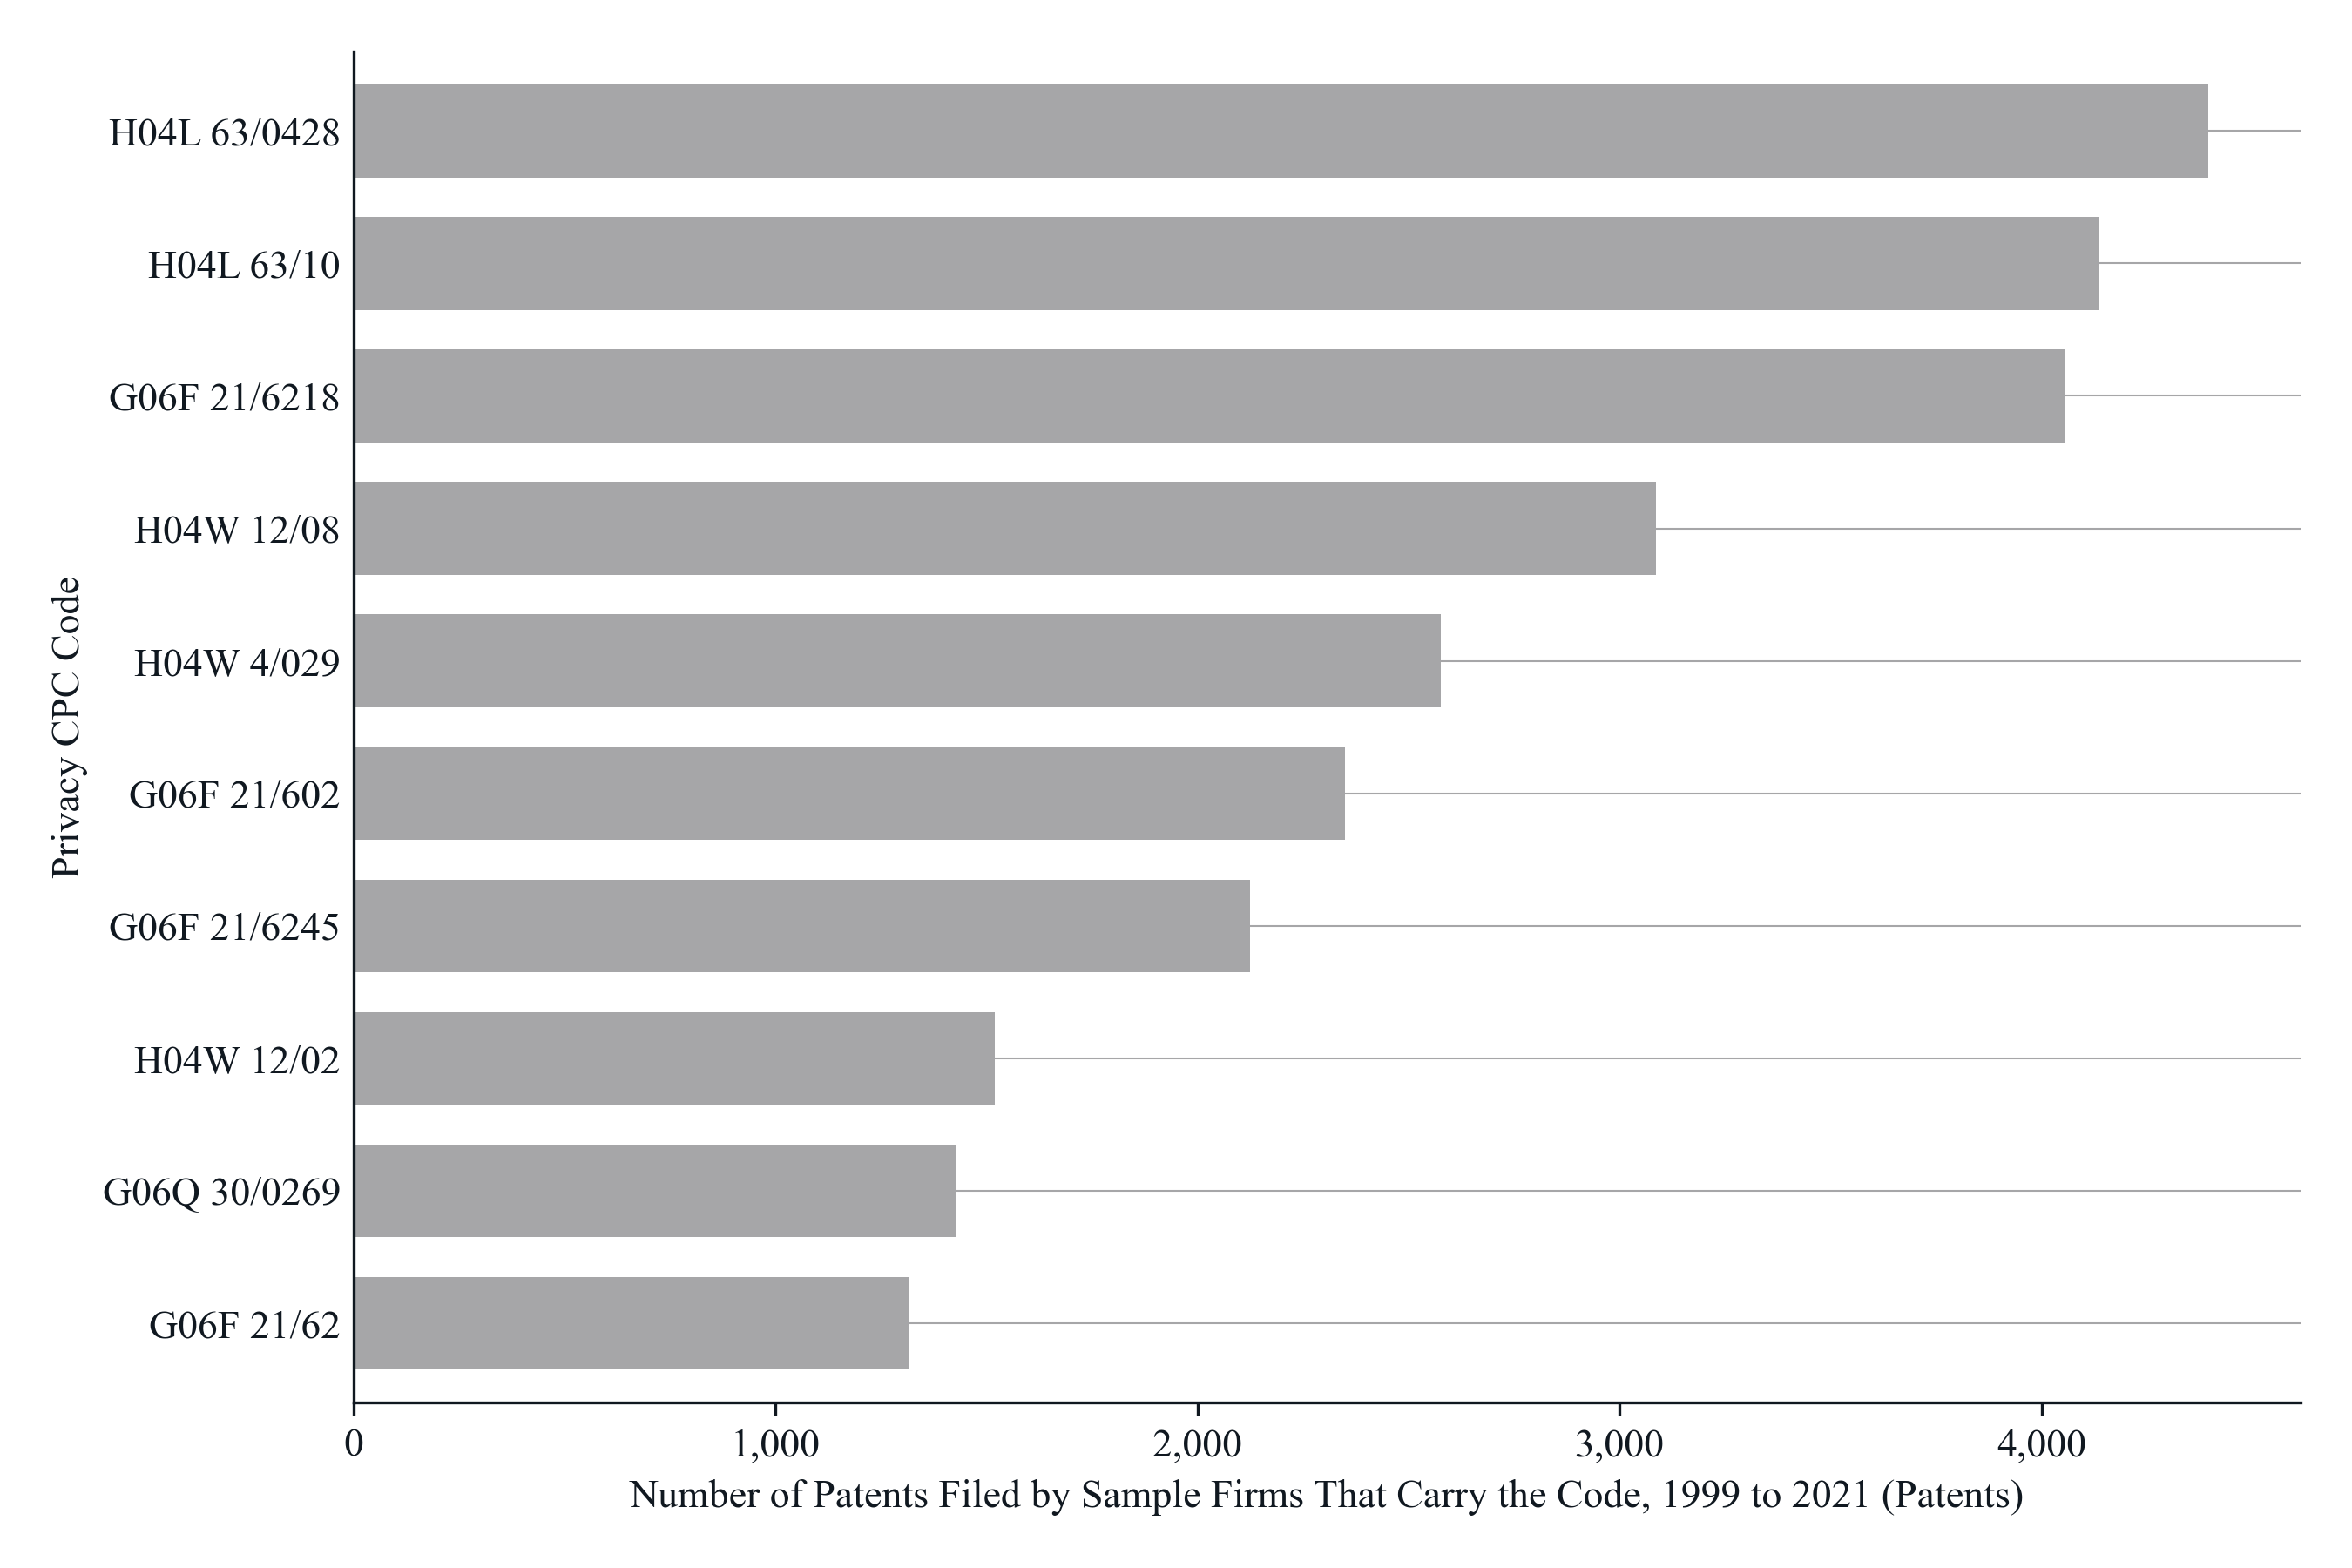

*Notes*: Each bar is the number of patents filed in 1999 to 2021 by the sample firms that carry the CPC code, the ten codes of the privacy list with the most such patents, the largest at the top. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes); a patent counts under every listed code it carries, so the bars overlap and do not add up to the 33,986 privacy patents. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1; 1,238,690 of their patents were filed in the period. The codes and their definitions from the list: H04L 63/0428, wherein the data content is protected, e.g. by encrypting or encapsulating the payload; H04L 63/10, for controlling access to devices or network resources; G06F 21/6218, to a system of files or objects, e.g. local or distributed file system or database; H04W 12/08, Access security; H04W 4/029, Location-based management or tracking services; G06F 21/602, Providing cryptographic facilities or services; G06F 21/6245, Protecting personal data, e.g. for financial or medical purposes; H04W 12/02, Protecting privacy or anonymity, e.g. protecting personally identifiable information [PII]; G06Q 30/0269, based on user profile or attribute; G06F 21/62, Protecting access to data via a platform, e.g. using keys or access control rules.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [8]:
figure_number = 1
table = by_code.head(TOP_N).reset_index(drop=True)
positions = np.arange(len(table))[::-1]  # the largest count at the top
figure_name = "fig_1_ten_privacy_cpc_codes_with_most_patents"
title = f"Ten Privacy CPC Codes With the Most Patents Filed by Sample Firms, {PERIOD_WORDS}"
x_title = f"Number of Patents Filed by Sample Firms That Carry the Code, {PERIOD_WORDS} (Patents)"
y_title = "Privacy CPC Code"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.2, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15)
axis.barh(positions, table["n_privacy_patents"], color=GREY, height=BAR_HEIGHT, zorder=2)
axis.set_yticks(positions, labels=table["cpc_display"])
axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
axis.set_xlim(0, table["n_privacy_patents"].max() * 1.05)
axis.xaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.tick_params(axis="y", length=0)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"

definitions = "; ".join(f"{code}, {definition}" for code, definition in zip(table["cpc_display"], table["definition"]))
notes = (f"Each bar is the number of patents filed in {PERIOD_WORDS} by the sample firms that carry the CPC code, the ten codes of the privacy list with the most such patents, "
         f"the largest at the top. {PRIVACY_WORDS}; a patent counts under every listed code it carries, so the bars overlap and do not add up to the {len(privacy_patents):,} privacy patents. "
         f"The sample firms are {SAMPLE_WORDS}; {len(patents):,} of their patents were filed in the period. The codes and their definitions from the list: {definitions}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 9. Figure 2: the ten firms with the most privacy patents

Horizontal GREY bars, the firm with the most privacy patents at the top; each patent counts once for its firm. Firm names are Compustat's.


**Figure 2. Ten Sample Firms With the Most Privacy Patents Filed, 1999 to 2021**

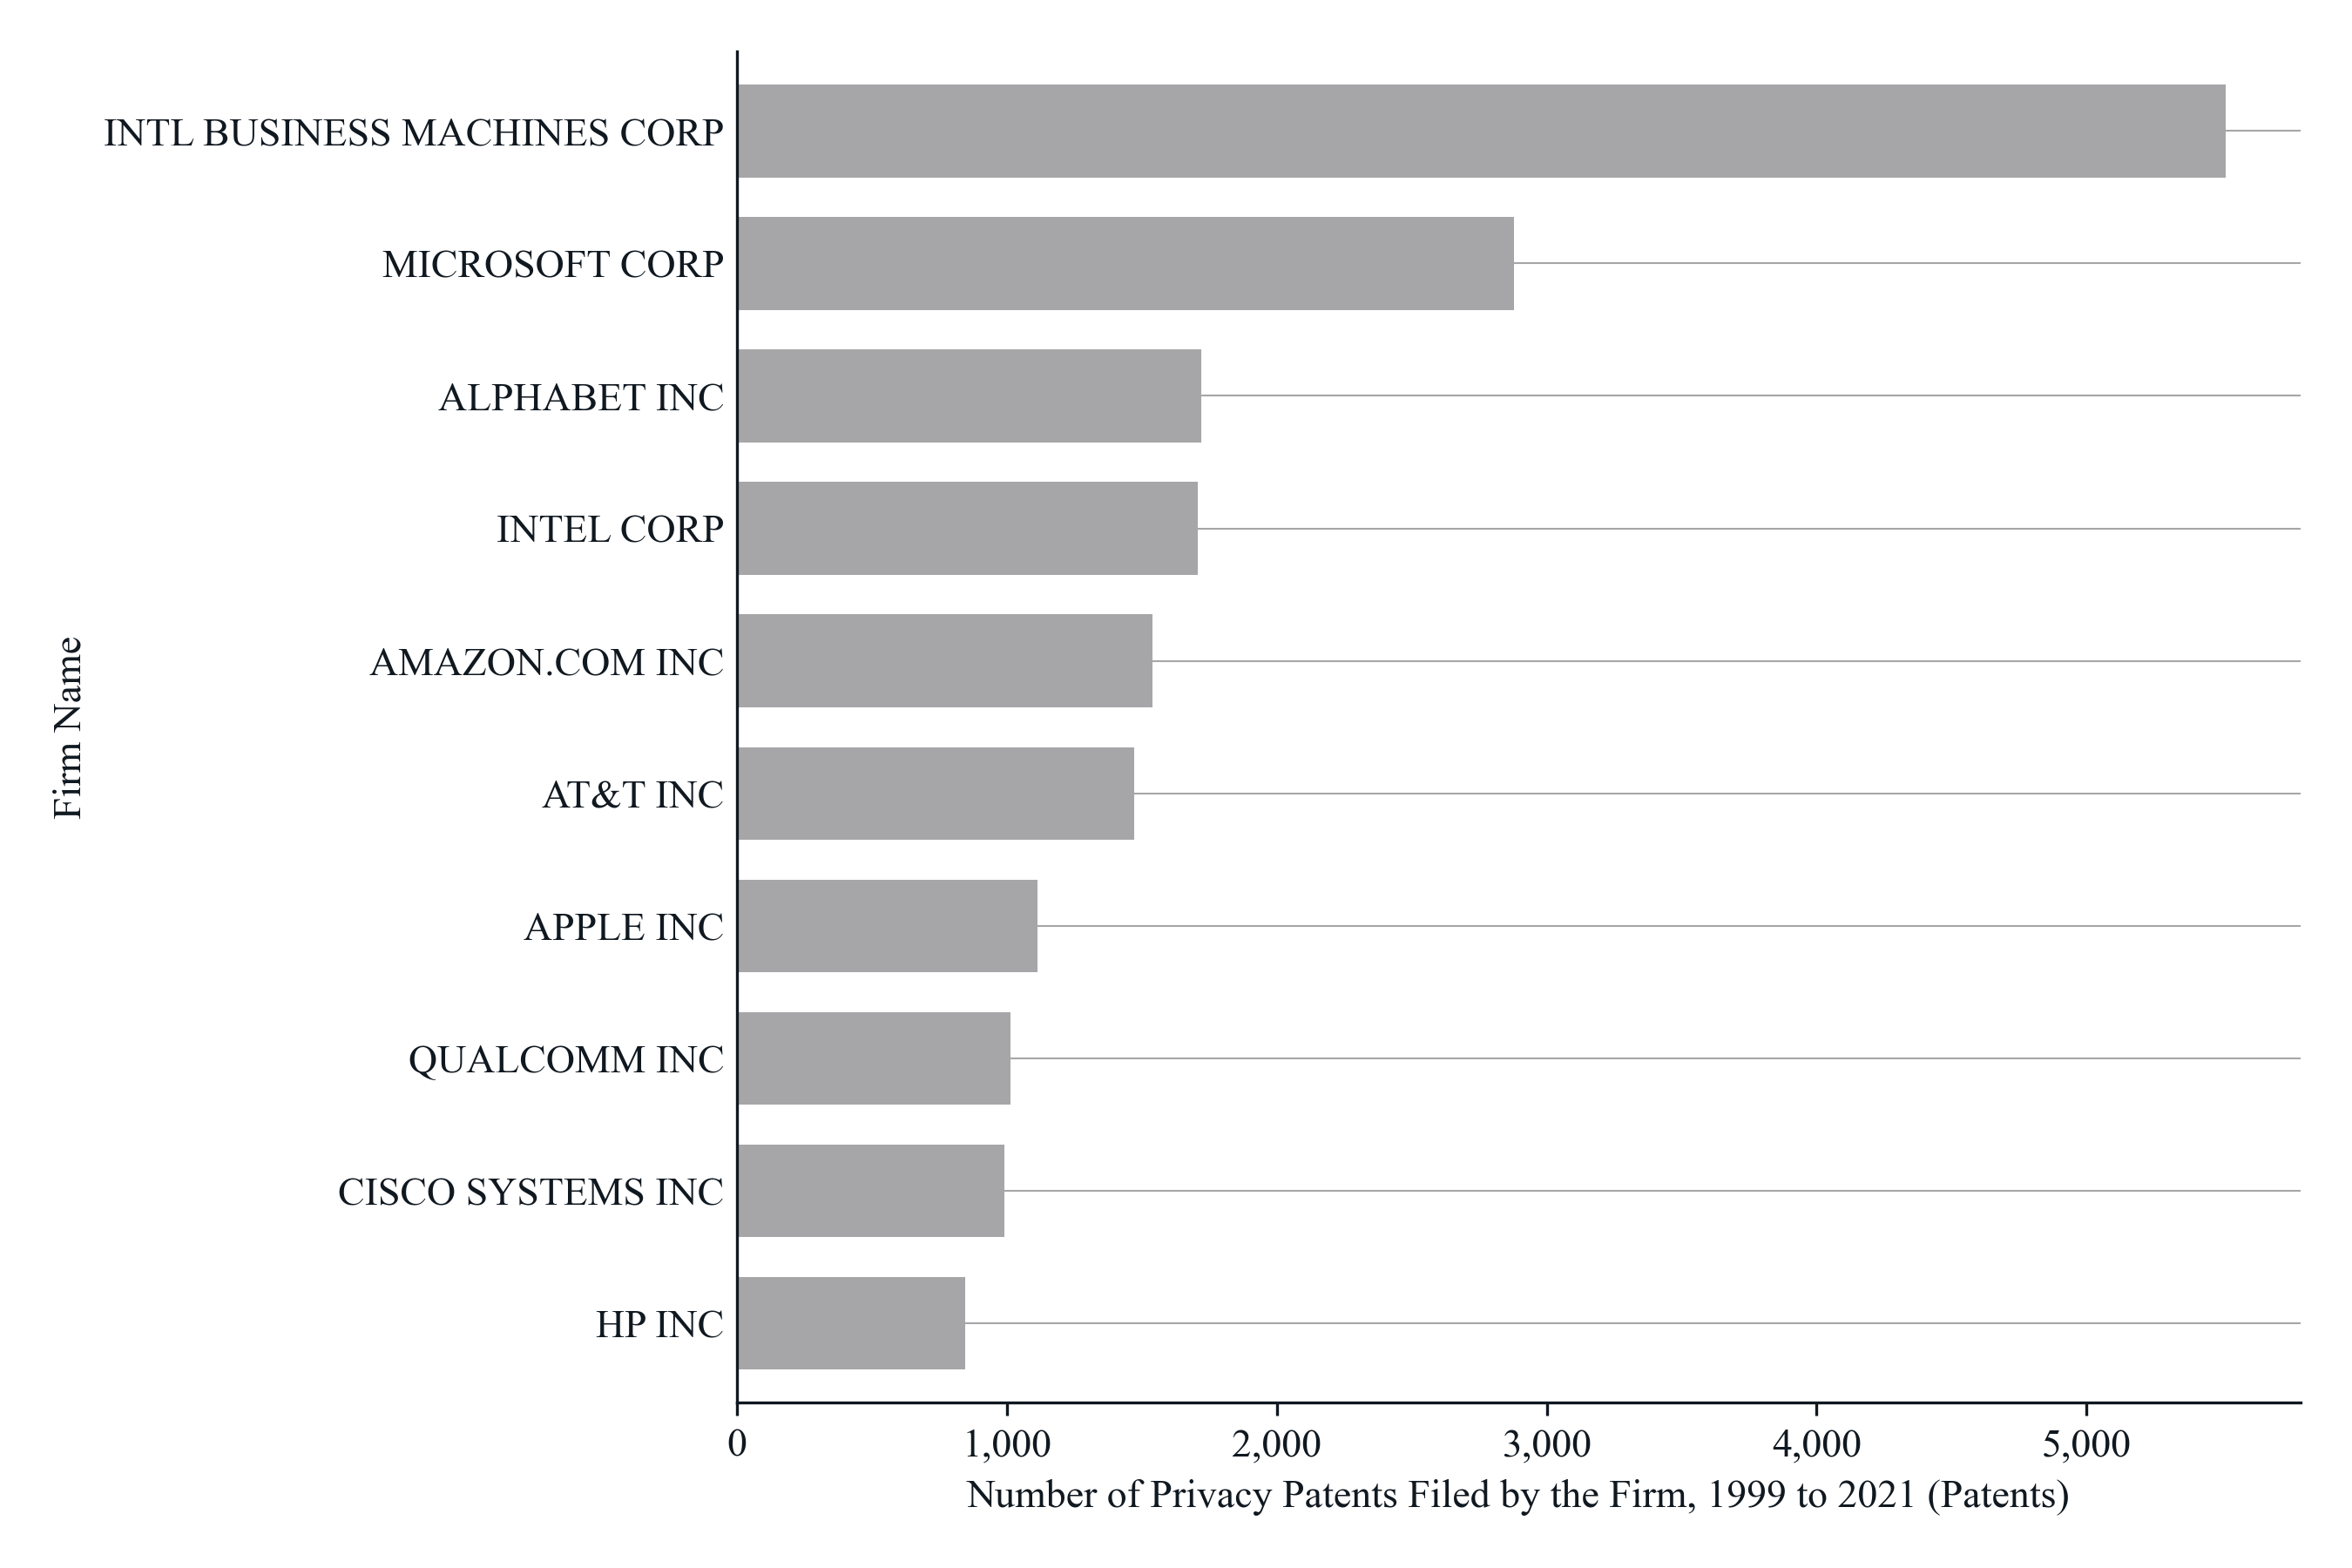

*Notes*: Each bar is the number of privacy patents filed in 1999 to 2021 by the firm, the ten sample firms with the most, the largest at the top; each patent counts once for the firm it is attributed to in T4.1.1. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). These ten firms account for 18,801 of the 33,986 privacy patents (55.3%); 279 of the 1,058 sample firms filed at least one. Firm names are Compustat company names. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [9]:
figure_number = 2
table = by_firm.head(TOP_N).reset_index(drop=True)
positions = np.arange(len(table))[::-1]
figure_name = "fig_2_ten_firms_with_most_privacy_patents"
title = f"Ten Sample Firms With the Most Privacy Patents Filed, {PERIOD_WORDS}"
x_title = f"Number of Privacy Patents Filed by the Firm, {PERIOD_WORDS} (Patents)"
y_title = "Firm Name"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.3, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15)
axis.barh(positions, table["n_privacy_patents"], color=GREY, height=BAR_HEIGHT, zorder=2)
axis.set_yticks(positions, labels=table["conm"])
axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
axis.set_xlim(0, table["n_privacy_patents"].max() * 1.05)
axis.xaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.tick_params(axis="y", length=0)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"

share_top = table["n_privacy_patents"].sum() / len(privacy_patents)
notes = (f"Each bar is the number of privacy patents filed in {PERIOD_WORDS} by the firm, the ten sample firms with the most, the largest at the top; each patent counts once for the "
         f"firm it is attributed to in T4.1.1. {PRIVACY_WORDS}. These ten firms account for {table['n_privacy_patents'].sum():,} of the {len(privacy_patents):,} privacy patents "
         f"({share_top:.1%}); {N_EVER:,} of the {N_FIRMS:,} sample firms filed at least one. Firm names are Compustat company names. The sample firms are {SAMPLE_WORDS}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 10. Figure 3: privacy patents by NAICS two-digit sector, all sectors

The T3.9.3 layout: one horizontal GREY bar per sector, the sector with the most privacy patents at the top, and a tick label with the sector name, its NAICS codes, and its number of sample firms. All sectors are drawn, including those without any privacy patent.


**Figure 3. Privacy Patents Filed by Sample Firms by NAICS Two-Digit Sector, 1999 to 2021**

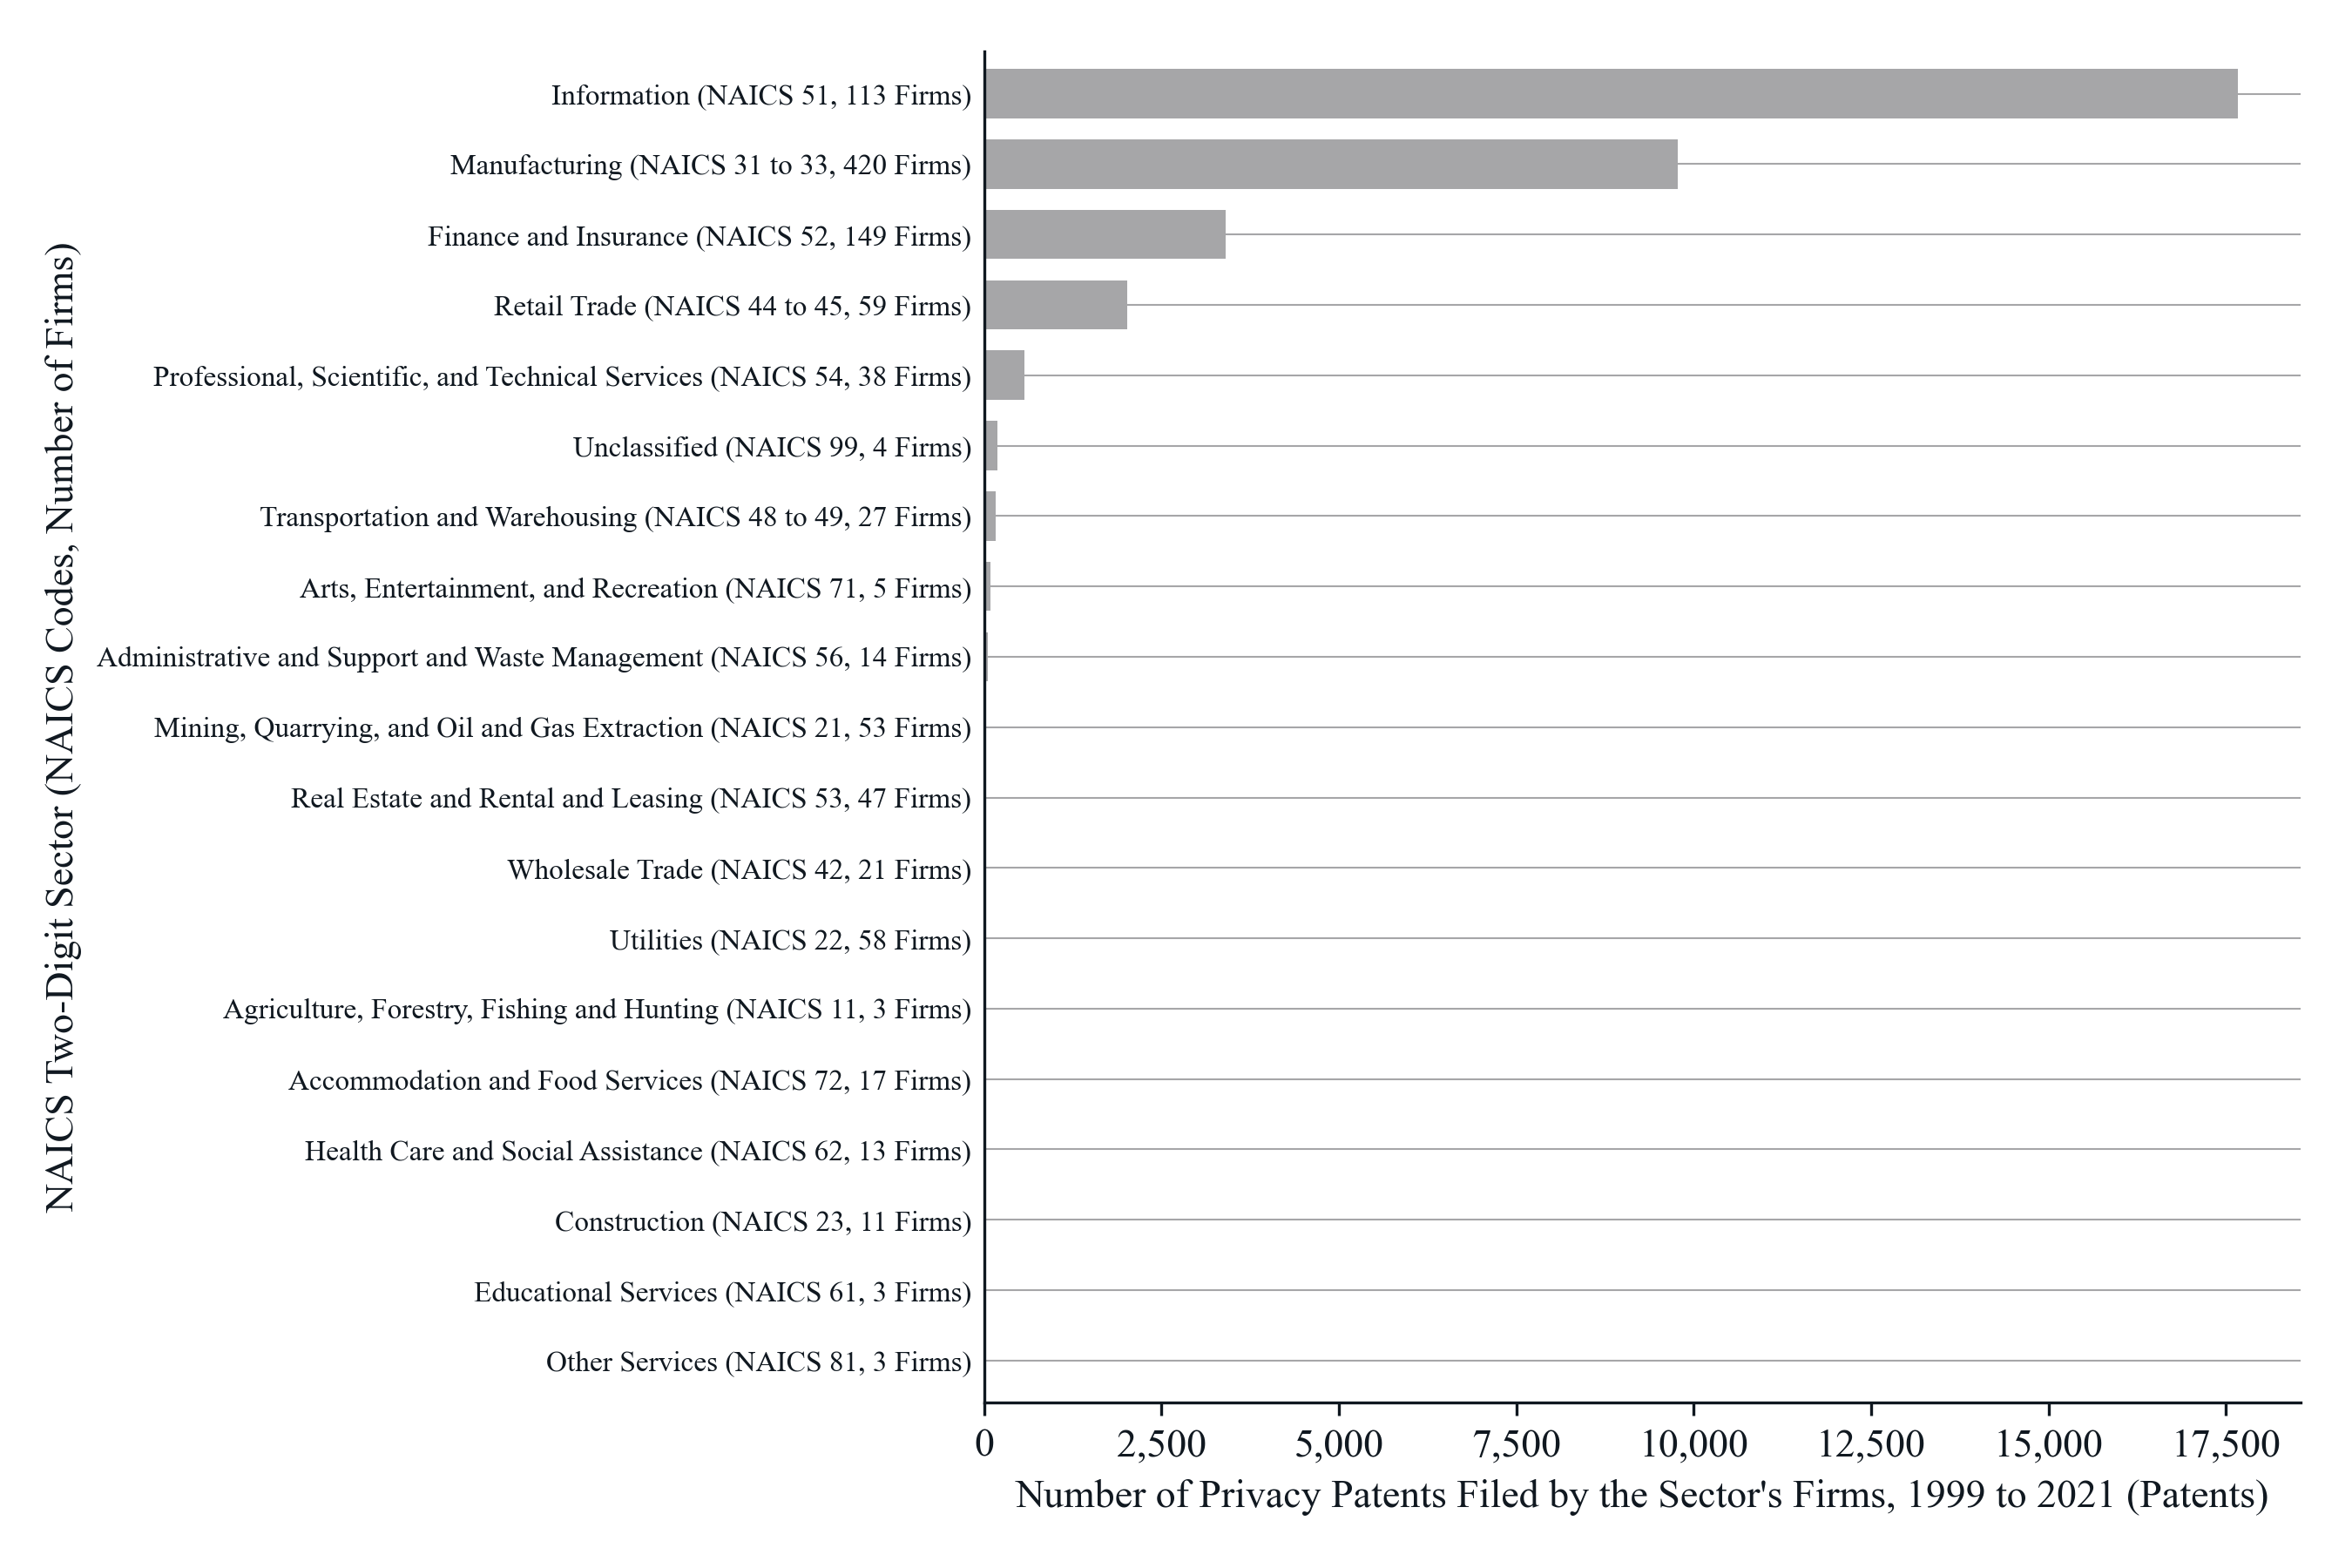

*Notes*: Each bar is the number of privacy patents filed in 1999 to 2021 by the firms of the sector, all 19 sectors of the sample, the largest at the top. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing; each tick label gives the codes and the number of sample firms in the sector. Sectors without any privacy patent: Construction, Educational Services, Other Services. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [10]:
figure_number = 3
table = by_sector.reset_index(drop=True)
positions = np.arange(len(table))[::-1]
labels = [f"{SECTOR_TITLES[sector]} (NAICS {codes}, {n:,} Firms)" for sector, codes, n in zip(table["sector"], table["codes"], table["n_firms"])]
figure_name = "fig_3_privacy_patents_by_sector_naics2"
title = f"Privacy Patents Filed by Sample Firms by NAICS Two-Digit Sector, {PERIOD_WORDS}"
x_title = f"Number of Privacy Patents Filed by the Sector's Firms, {PERIOD_WORDS} (Patents)"
y_title = "NAICS Two-Digit Sector (NAICS Codes, Number of Firms)"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.42, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15)
axis.barh(positions, table["n_privacy_patents"], color=GREY, height=BAR_HEIGHT, zorder=2)
axis.set_yticks(positions, labels=labels)
axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
axis.set_xlim(0, table["n_privacy_patents"].max() * 1.05)
axis.xaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.tick_params(axis="y", length=0, labelsize=8)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"

zero_sectors = table.loc[table["n_privacy_patents"].eq(0), "sector"].map(SECTOR_TITLES).tolist()
notes = (f"Each bar is the number of privacy patents filed in {PERIOD_WORDS} by the firms of the sector, all {len(table)} sectors of the sample, the largest at the top. {PRIVACY_WORDS}. "
         "The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation "
         f"and warehousing; each tick label gives the codes and the number of sample firms in the sector. Sectors without any privacy patent: {', '.join(zero_sectors) if zero_sectors else 'none'}. "
         f"The sample firms are {SAMPLE_WORDS}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 11. Figure 4: privacy patents by NAICS three-digit subsector, the ten highest and the ten lowest

Among subsectors with at least `MIN_FIRMS_NAICS3` sample firms, the ten with the most privacy patents and the ten with the fewest, in one ranking with an empty row between the two groups; ties at the bottom are ordered by the number of firms. The tick label gives the subsector name, its code, and its number of firms.


**Figure 4. Privacy Patents Filed by Sample Firms by NAICS Three-Digit Subsector, Ten Highest and Ten Lowest Subsectors, 1999 to 2021**

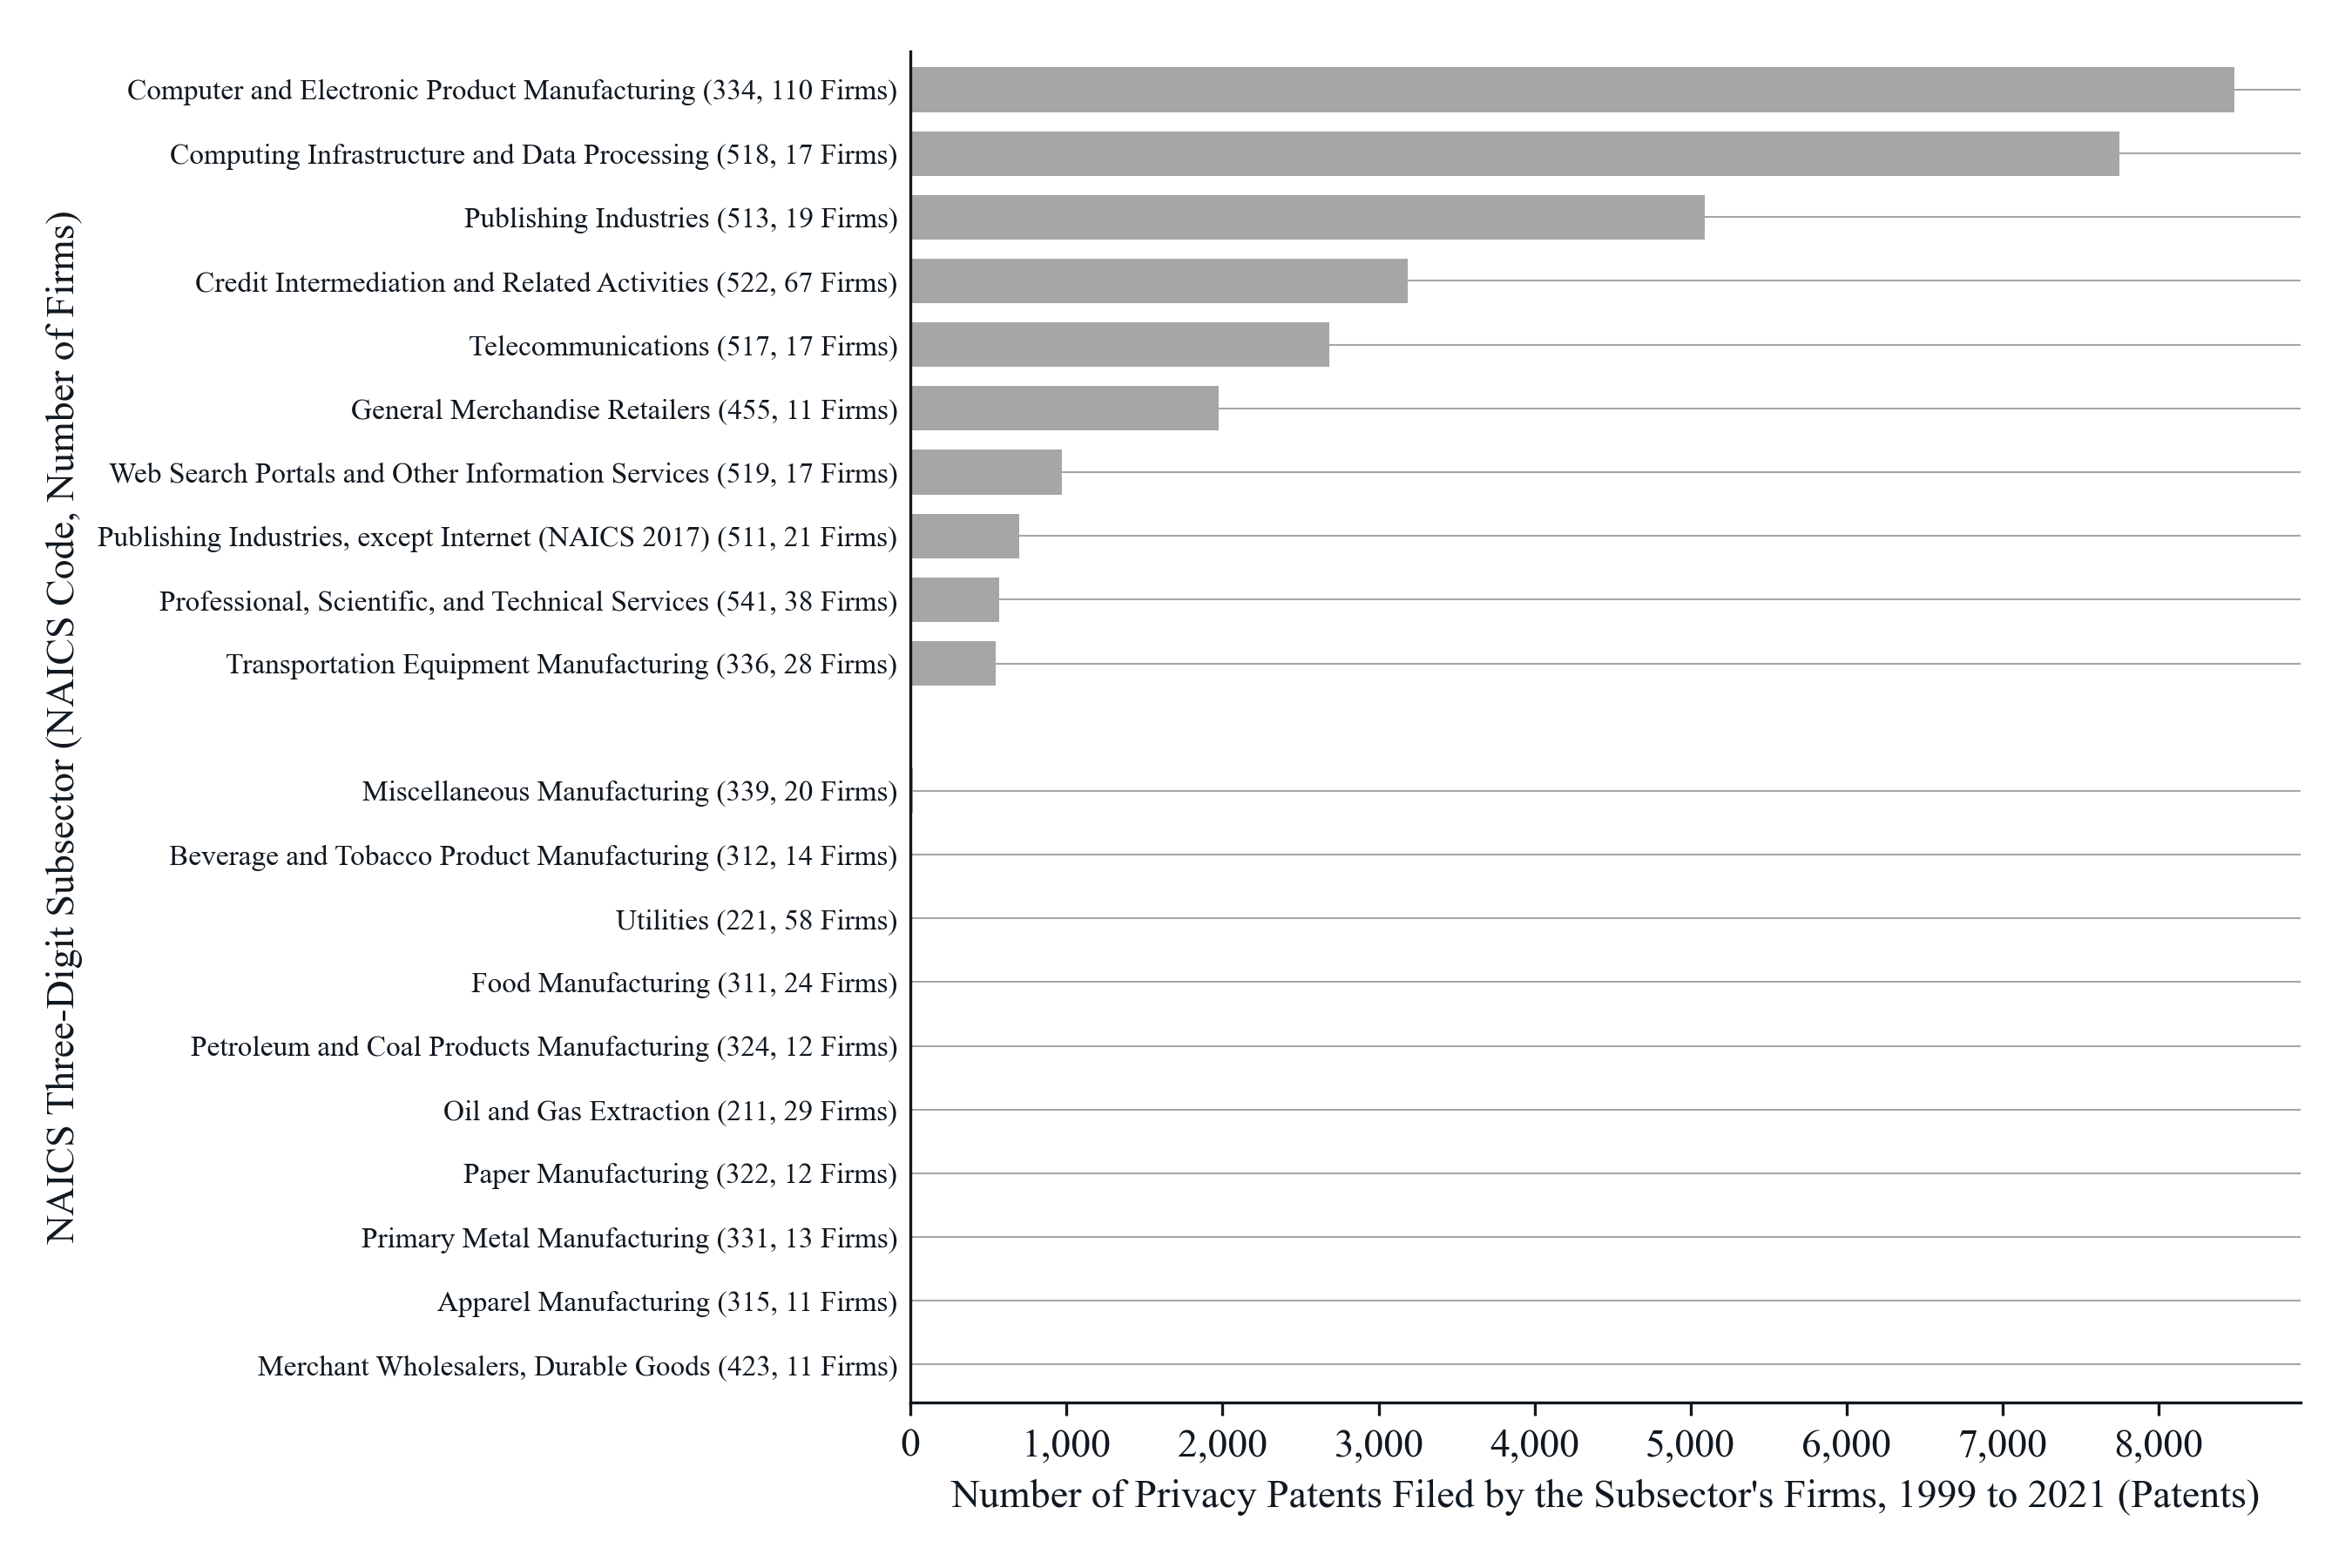

*Notes*: Each bar is the number of privacy patents filed in 1999 to 2021 by the firms of the subsector. Of the 85 three-digit subsectors in the sample, 30 have at least 10 sample firms; the upper group is the ten of those with the most privacy patents and the lower group, below the empty row, the ten with the fewest, each ordered from the most at the top; subsectors with the same count are ordered by their number of firms. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). The subsector is the firm's Compustat NAICS code cut to three digits, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise; each tick label gives the code and the number of sample firms. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [11]:
figure_number = 4
eligible = by_subsector.loc[by_subsector["n_firms"].ge(MIN_FIRMS_NAICS3)].reset_index(drop=True)  # already sorted by patents, then firms, descending
top_rows = eligible.head(TOP_N)
bottom_rows = eligible.tail(TOP_N)
table = pd.concat([top_rows, bottom_rows]).reset_index(drop=True)
positions = np.concatenate([np.arange(TOP_N)[::-1] + TOP_N + 1, np.arange(TOP_N)[::-1]])  # one empty row between the two groups
labels = [f"{subsector} ({code}, {n:,} Firms)" for subsector, code, n in zip(table["subsector"], table["naics3"], table["n_firms"])]
figure_name = "fig_4_privacy_patents_by_subsector_naics3_ten_highest_and_lowest"
title = f"Privacy Patents Filed by Sample Firms by NAICS Three-Digit Subsector, Ten Highest and Ten Lowest Subsectors, {PERIOD_WORDS}"
x_title = f"Number of Privacy Patents Filed by the Subsector's Firms, {PERIOD_WORDS} (Patents)"
y_title = "NAICS Three-Digit Subsector (NAICS Code, Number of Firms)"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.42, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15)
axis.barh(positions, table["n_privacy_patents"], color=GREY, height=BAR_HEIGHT, zorder=2)
axis.set_yticks(positions, labels=labels)
axis.set_ylim(-0.6, positions.max() + 0.6)
axis.set_xlim(0, table["n_privacy_patents"].max() * 1.05)
axis.xaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.tick_params(axis="y", length=0, labelsize=8)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"

notes = (f"Each bar is the number of privacy patents filed in {PERIOD_WORDS} by the firms of the subsector. Of the {len(by_subsector)} three-digit subsectors in the sample, "
         f"{len(eligible)} have at least {MIN_FIRMS_NAICS3} sample firms; the upper group is the ten of those with the most privacy patents and the lower group, below the empty row, "
         f"the ten with the fewest, each ordered from the most at the top; subsectors with the same count are ordered by their number of firms. {PRIVACY_WORDS}. The subsector is the "
         "firm's Compustat NAICS code cut to three digits, named by NAICS 2022 where the code exists in that vintage and by the older vintage otherwise; each tick label gives the code and "
         f"the number of sample firms. The sample firms are {SAMPLE_WORDS}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 12. Figure 5: firms that ever filed a privacy patent and firms that never did

Two vertical bars, the count of sample firms in each group: RED for firms with at least one privacy patent in the period, BLUE for firms with none. The tick labels name the groups, so no legend is drawn.


**Figure 5. Number of Sample Firms That Filed at Least One Privacy Patent and That Filed None, 1999 to 2021**

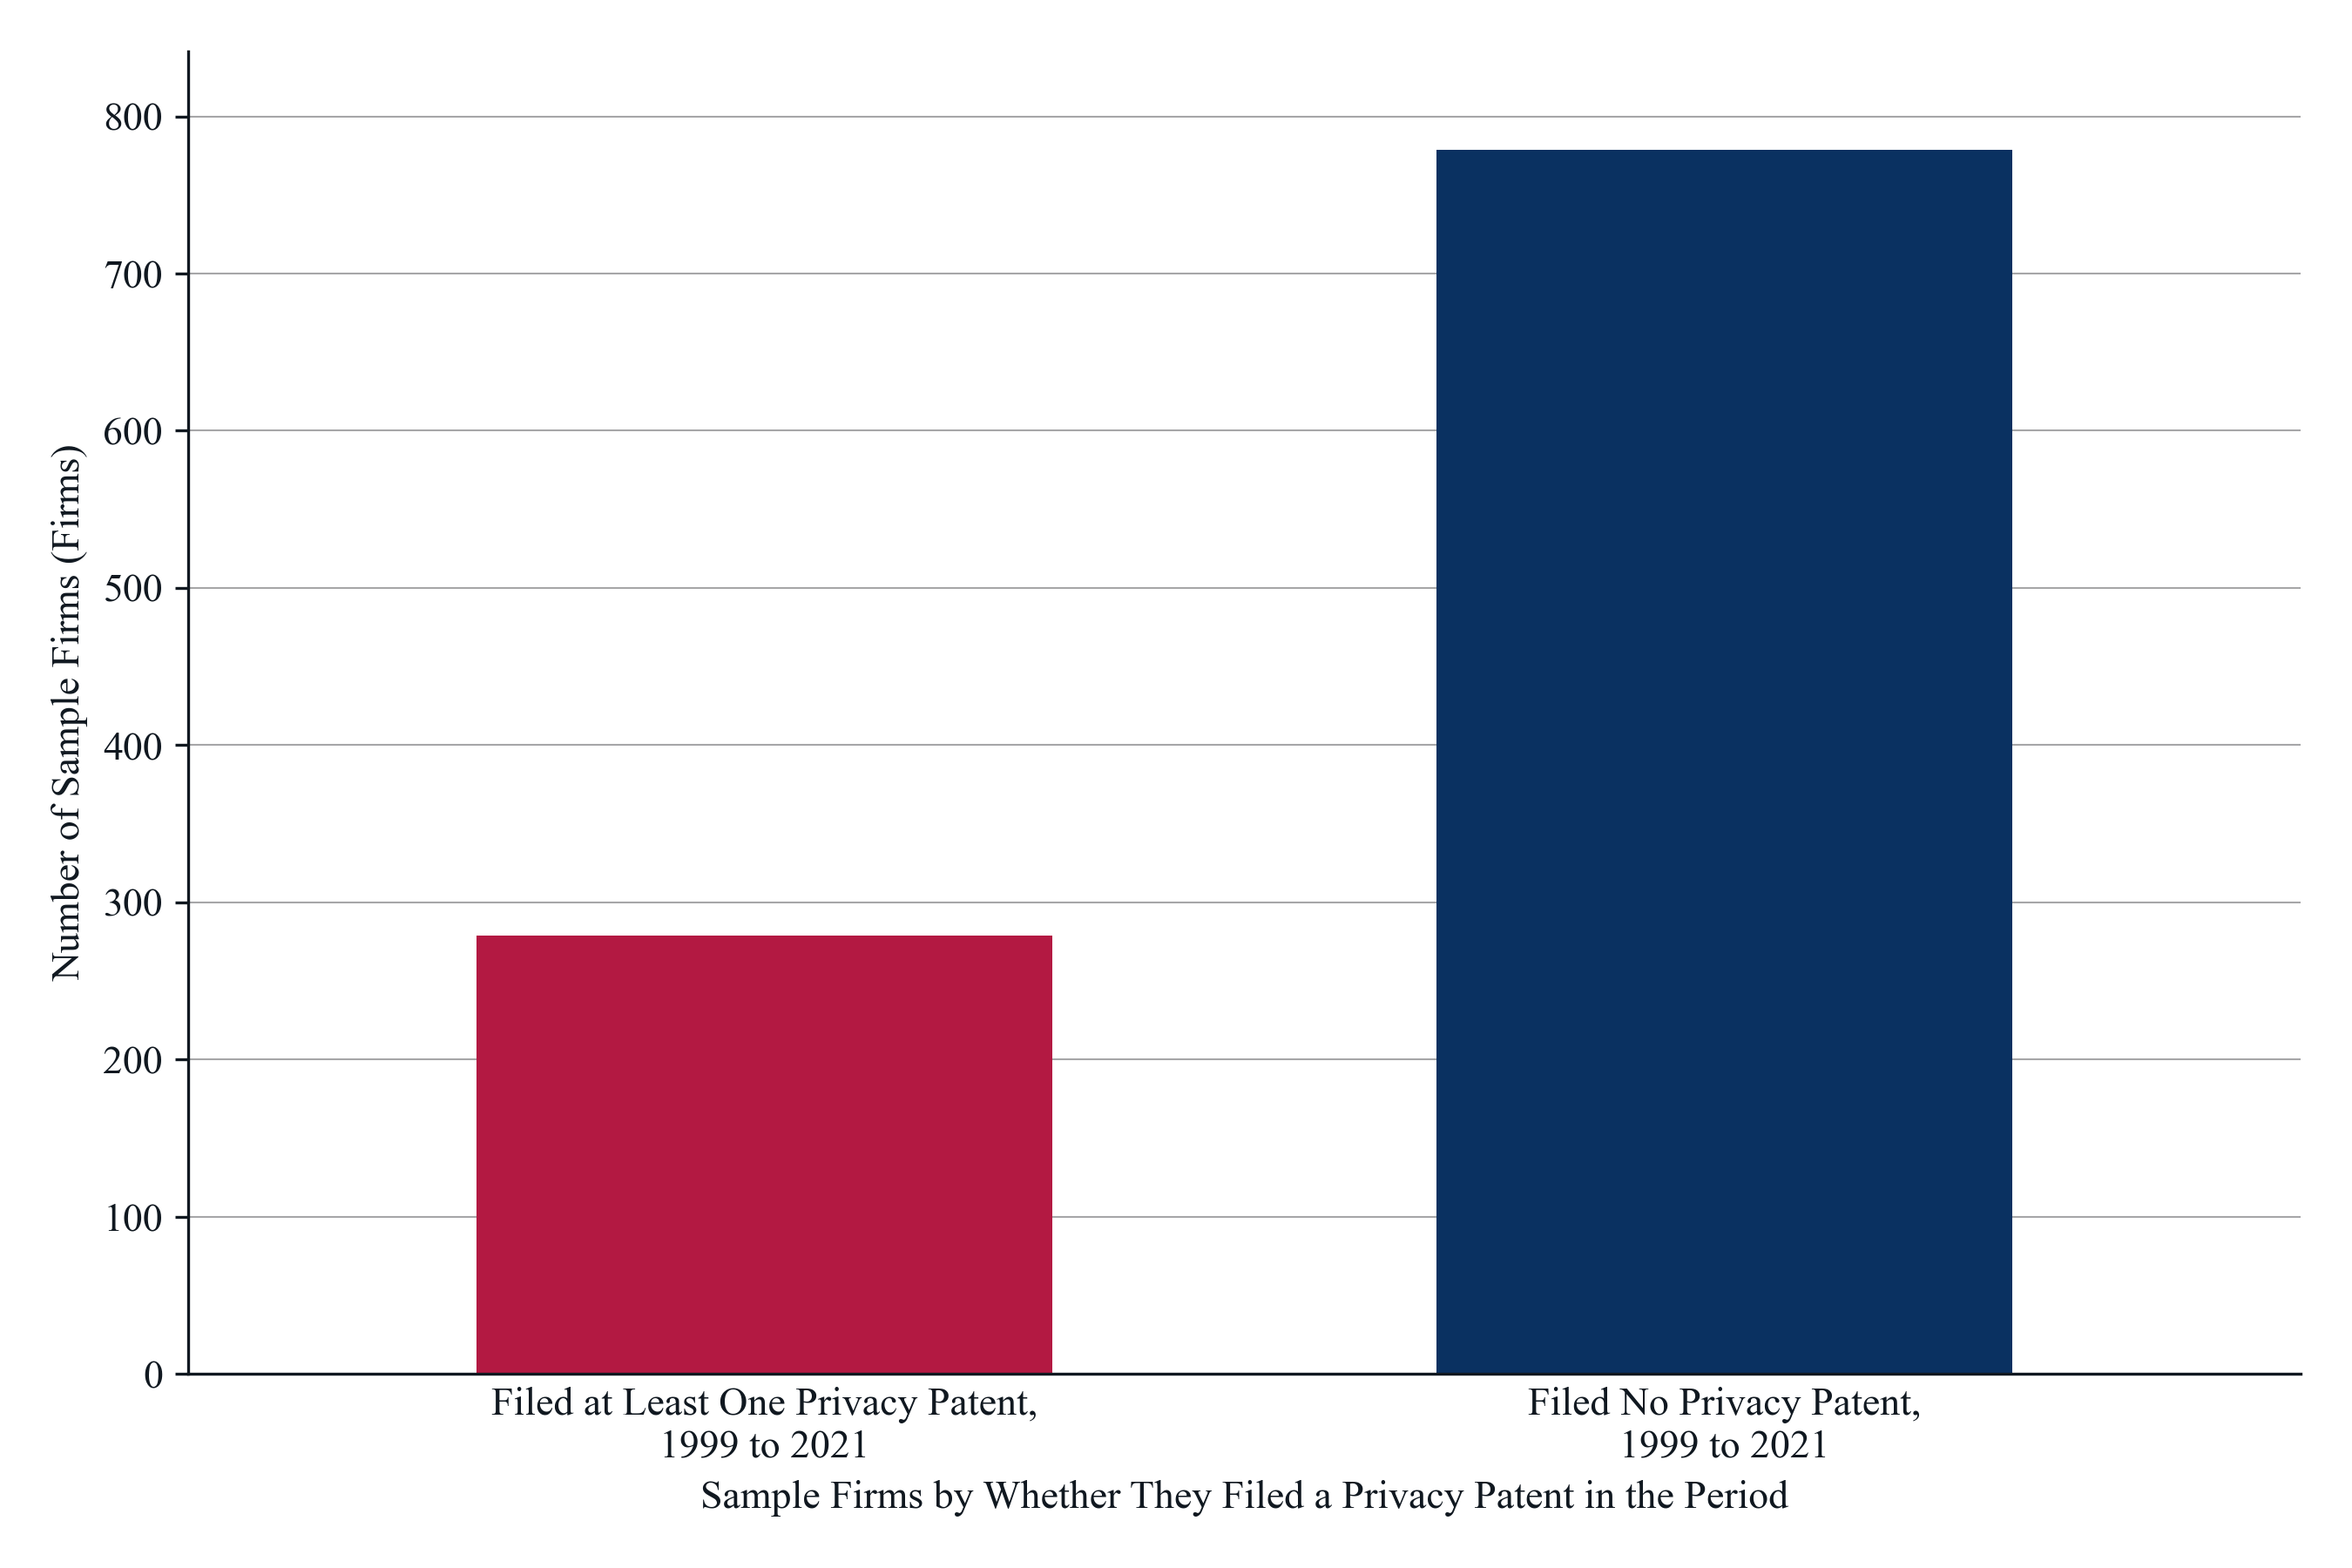

*Notes*: The left bar (RED) is the number of sample firms with at least one privacy patent filed in 1999 to 2021, 279 firms (26.4% of the sample); the right bar (BLUE) is the number with none, 779 firms. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). A patent is attributed to a firm through the CRSP-Compustat link in force on its filing date (T4.1.1), so a firm with no linked permno in a year cannot have a patent in that year. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [12]:
figure_number = 5
counts = [N_EVER, N_NEVER]
labels = [f"Filed at Least One Privacy Patent,\n{PERIOD_WORDS}", f"Filed No Privacy Patent,\n{PERIOD_WORDS}"]
figure_name = "fig_5_firms_ever_vs_never_filed_privacy_patent"
title = f"Number of Sample Firms That Filed at Least One Privacy Patent and That Filed None, {PERIOD_WORDS}"
x_title = "Sample Firms by Whether They Filed a Privacy Patent in the Period"
y_title = "Number of Sample Firms (Firms)"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.15)
axis.bar([0, 1], counts, color=[RED, BLUE], width=0.6, zorder=2)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=3)
axis.set_xticks([0, 1], labels=labels)
axis.set_xlim(-0.6, 1.6)
axis.set_ylim(0, max(counts) * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.tick_params(axis="x", length=0)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"

notes = (f"The left bar (RED) is the number of sample firms with at least one privacy patent filed in {PERIOD_WORDS}, {N_EVER:,} firms ({N_EVER / N_FIRMS:.1%} of the sample); "
         f"the right bar (BLUE) is the number with none, {N_NEVER:,} firms. {PRIVACY_WORDS}. A patent is attributed to a firm through the CRSP-Compustat link in force on its "
         f"filing date (T4.1.1), so a firm with no linked permno in a year cannot have a patent in that year. The sample firms are {SAMPLE_WORDS}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 13. Figure 6: firms that ever filed and firms that never did, by NAICS two-digit sector

One horizontal bar per sector, stacked: RED for the firms with at least one privacy patent, BLUE for the firms with none, the bar's length the sector's number of sample firms. Sectors are ordered by the number of firms that filed, the most at the top. A legend below the X-title names the two groups.


**Figure 6. Number of Sample Firms That Filed at Least One Privacy Patent and That Filed None by NAICS Two-Digit Sector, 1999 to 2021**

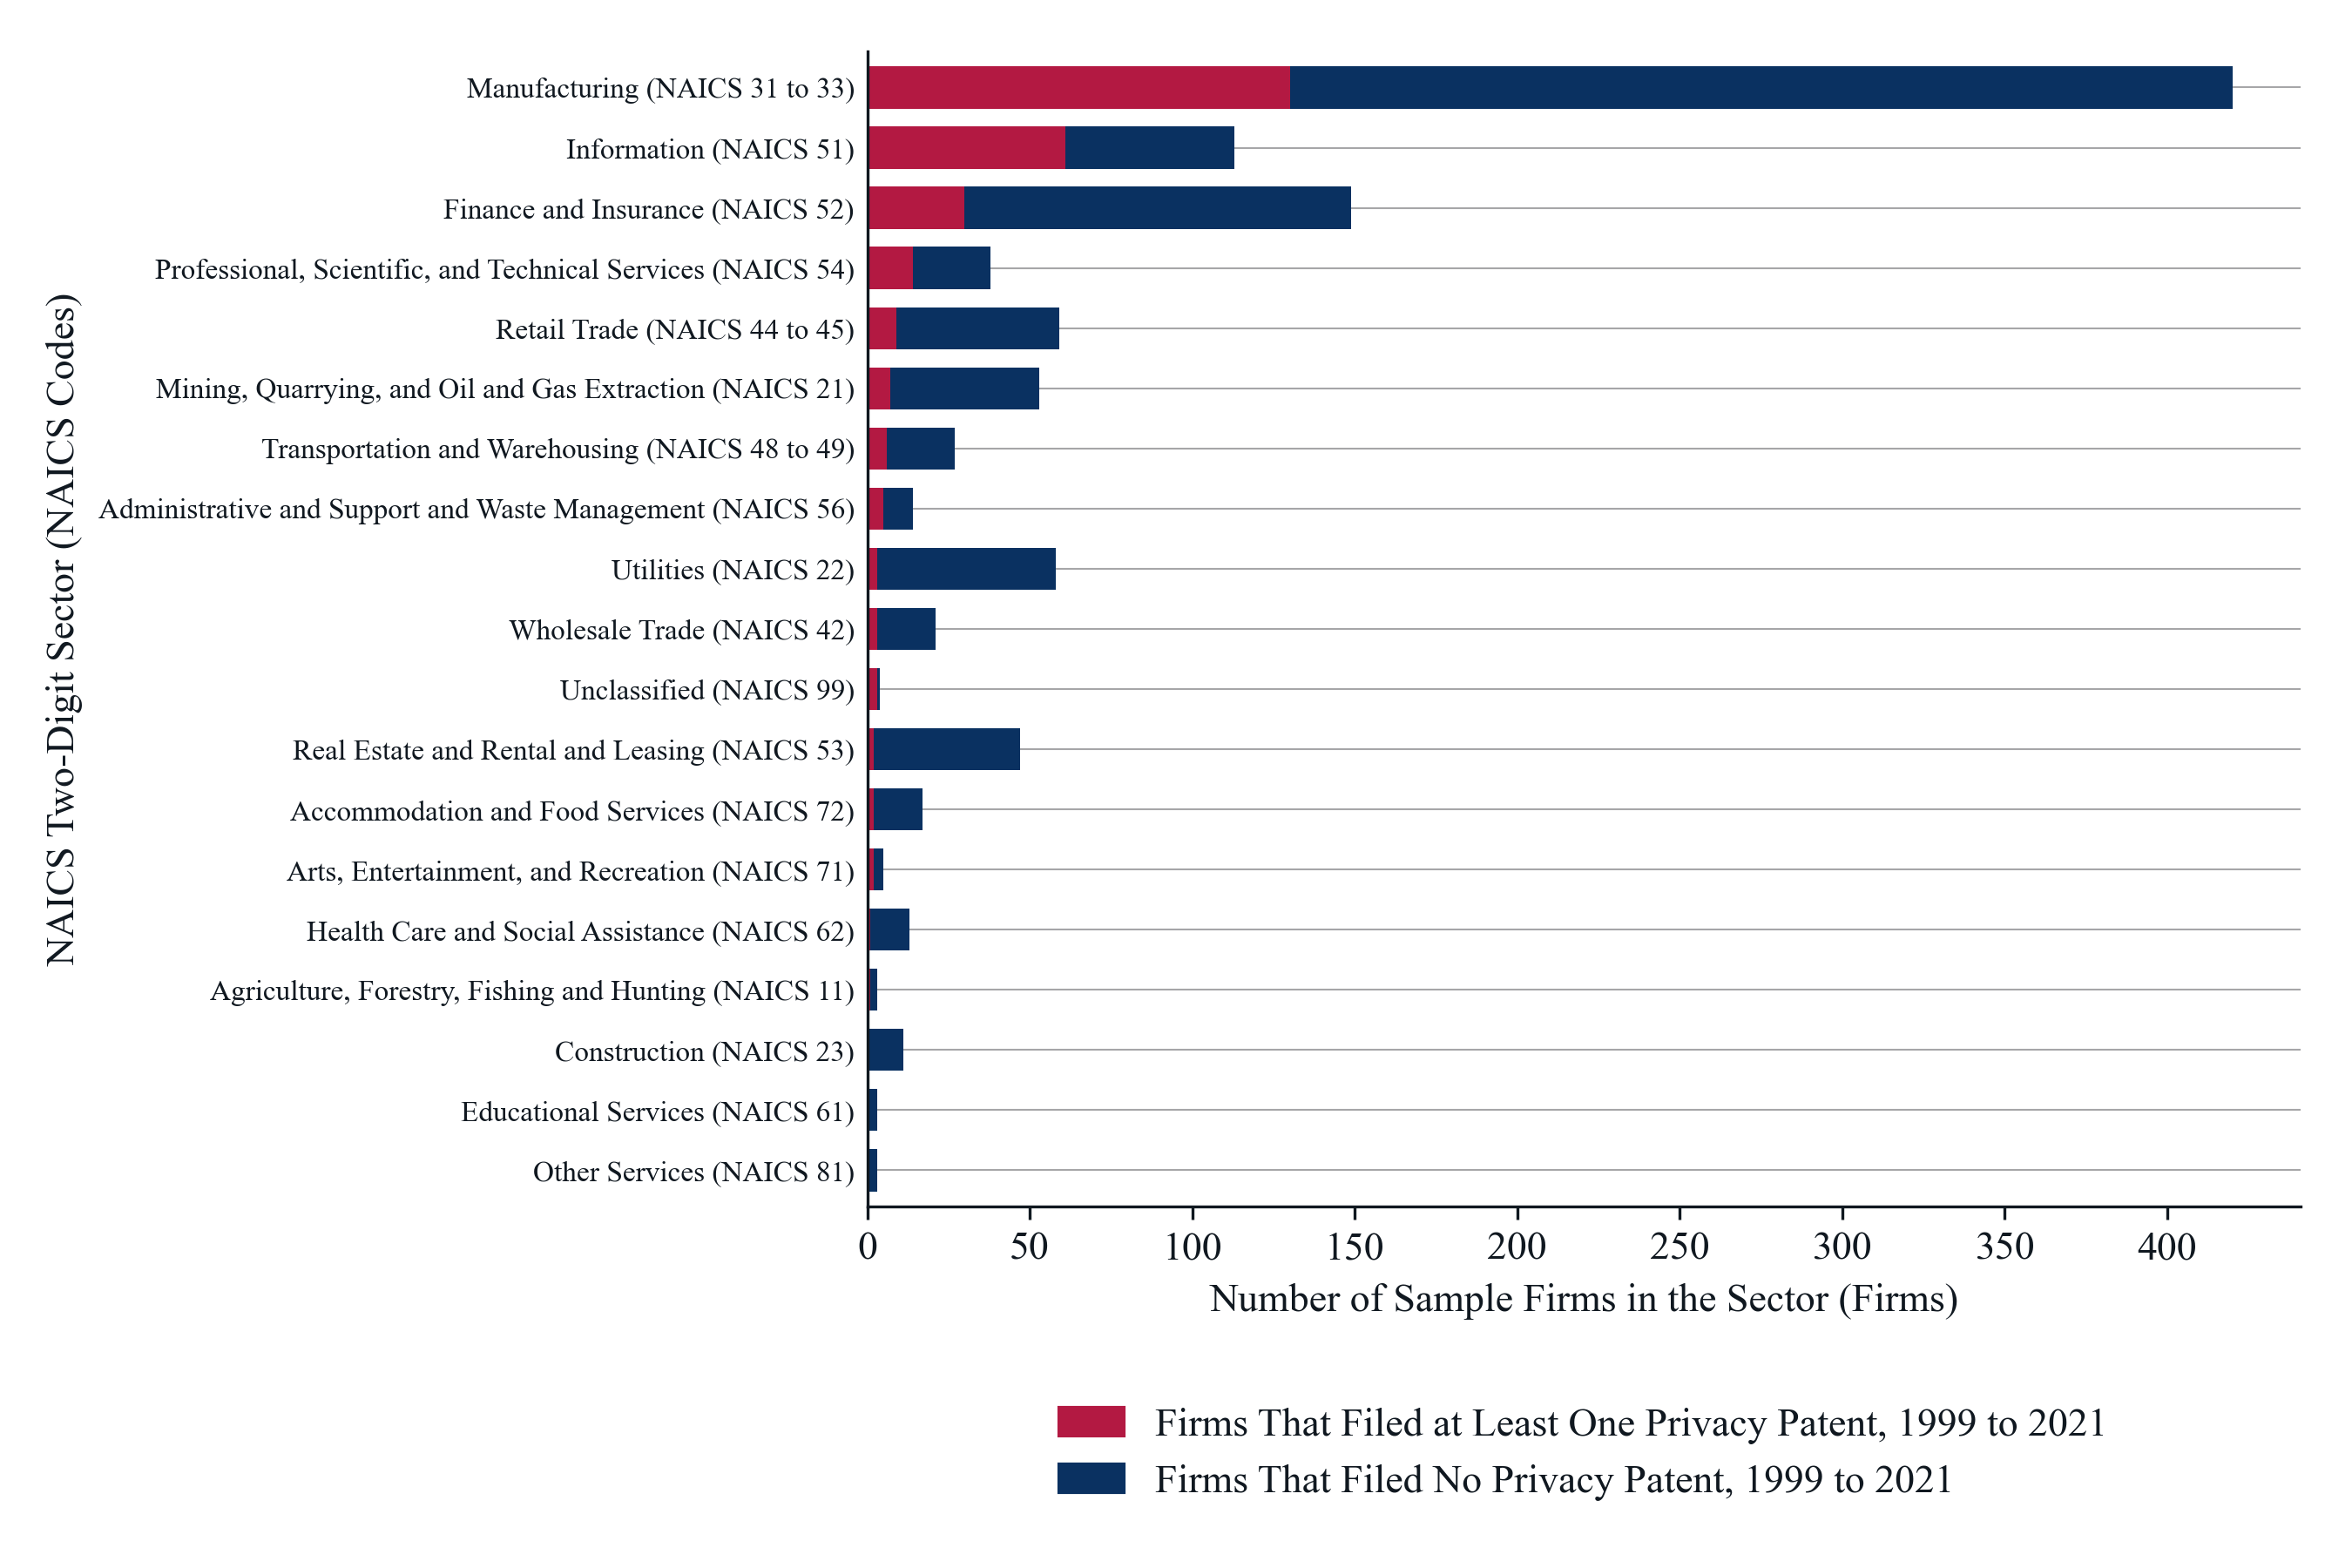

*Notes*: Each bar is the number of sample firms in the sector, split into the firms with at least one privacy patent filed in 1999 to 2021 (RED, drawn from zero) and the firms with none (BLUE, stacked to the right); sectors are ordered by the number of firms that filed, the most at the top (Manufacturing 130 of 420; Information 61 of 113; Finance and Insurance 30 of 149). A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). The sector is the firm's Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing. In all, 279 of the 1,058 sample firms filed at least one privacy patent. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [13]:
figure_number = 6
table = by_sector.sort_values(["n_firms_ever_filed", "n_firms"], ascending=[False, False]).reset_index(drop=True)
positions = np.arange(len(table))[::-1]
labels = [f"{SECTOR_TITLES[sector]} (NAICS {codes})" for sector, codes in zip(table["sector"], table["codes"])]
figure_name = "fig_6_firms_ever_vs_never_filed_by_sector_naics2"
title = f"Number of Sample Firms That Filed at Least One Privacy Patent and That Filed None by NAICS Two-Digit Sector, {PERIOD_WORDS}"
x_title = "Number of Sample Firms in the Sector (Firms)"
y_title = "NAICS Two-Digit Sector (NAICS Codes)"
LEGEND_COLUMNS = 1
legend_handles = [Patch(color=RED, label=f"Firms That Filed at Least One Privacy Patent, {PERIOD_WORDS}"), Patch(color=BLUE, label=f"Firms That Filed No Privacy Patent, {PERIOD_WORDS}")]

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.38, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)
axis.barh(positions, table["n_firms_ever_filed"], color=RED, height=BAR_HEIGHT, zorder=2)
axis.barh(positions, table["n_firms_never_filed"], left=table["n_firms_ever_filed"], color=BLUE, height=BAR_HEIGHT, zorder=2)
axis.set_yticks(positions, labels=labels)
axis.set_ylim(positions.min() - 0.6, positions.max() + 0.6)
axis.set_xlim(0, table["n_firms"].max() * 1.05)
axis.xaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.tick_params(axis="y", length=0, labelsize=8)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
# Legend: its top 0.5 cm below the X-title, its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room, which moves the X-title and the legend together.
x_title_box = axis.xaxis.label.get_window_extent(renderer)
axis_center = (axis.get_window_extent(renderer).x0 + axis.get_window_extent(renderer).x1) / 2 / figure.bbox.width
legend = figure.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height),
                       bbox_transform=figure.transFigure, ncol=LEGEND_COLUMNS, frameon=False, handlelength=1.6, columnspacing=2.0)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert legend_box.x0 >= margin_pixels and legend_box.x1 <= figure.bbox.width - margin_pixels, f"legend runs from {legend_box.x0 / figure.dpi:.2f} to {legend_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - legend_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor((axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height), transform=figure.transFigure)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert abs(legend_box.y0 - margin_pixels) <= 2, f"legend bottom at {legend_box.y0 / figure.dpi:.2f} inches"
assert axis.get_tightbbox(renderer).y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the top margin"

top_three = "; ".join(f"{SECTOR_TITLES[s]} {e:,} of {n:,}" for s, e, n in zip(table["sector"].head(3), table["n_firms_ever_filed"].head(3), table["n_firms"].head(3)))
notes = (f"Each bar is the number of sample firms in the sector, split into the firms with at least one privacy patent filed in {PERIOD_WORDS} (RED, drawn from zero) and the firms "
         f"with none (BLUE, stacked to the right); sectors are ordered by the number of firms that filed, the most at the top ({top_three}). {PRIVACY_WORDS}. The sector is the firm's "
         "Compustat NAICS code cut to two digits, with codes 31 to 33 merged into manufacturing, 44 to 45 into retail trade, and 48 to 49 into transportation and warehousing. "
         f"In all, {N_EVER:,} of the {N_FIRMS:,} sample firms filed at least one privacy patent. The sample firms are {SAMPLE_WORDS}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 14. Figure 7: privacy patents by filing year

One RED line with markers, the number of privacy patents filed in each year of the period; the Y-title reads "Privacy Patent Count" as requested.


**Figure 7. Privacy Patents Filed by Sample Firms by Filing Year, 1999 to 2021**

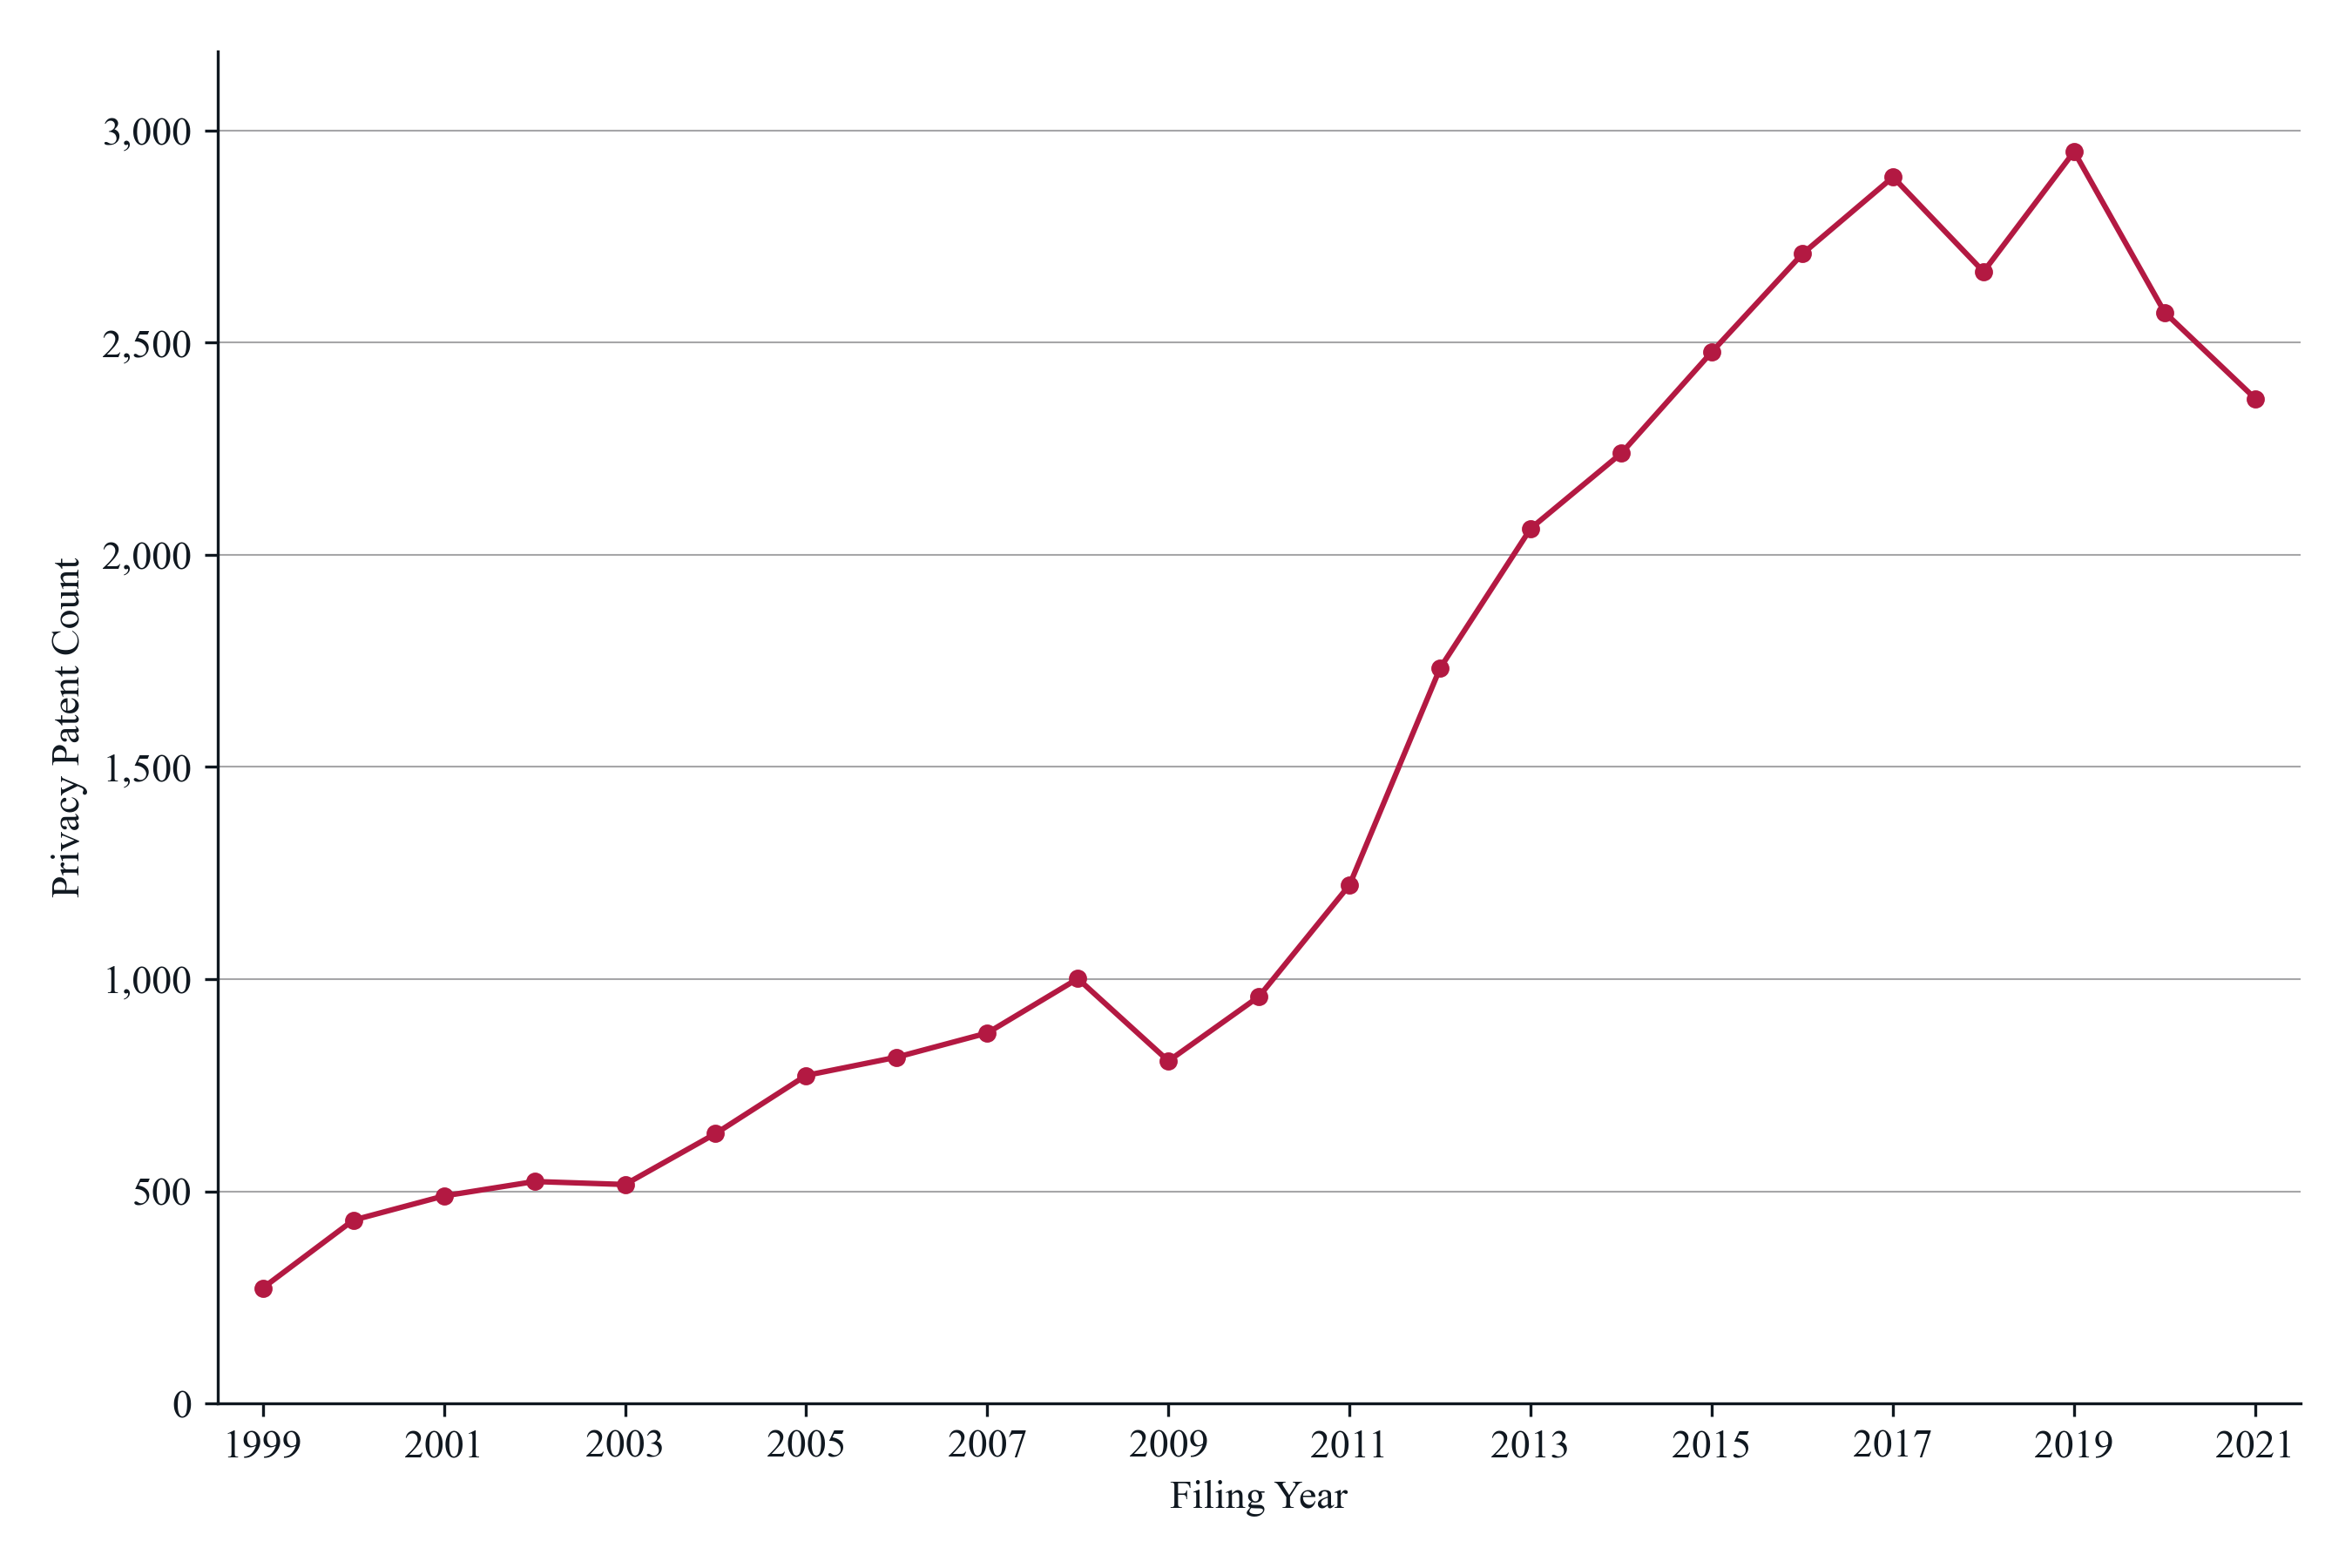

*Notes*: The line is the number of privacy patents filed by the sample firms in each year, 1999 to 2021, by the patent's filing date; 33,986 patents in all, from 272 in 1999 to a peak of 2,950 in 2019 and 2,368 in 2021. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [14]:
figure_number = 7
figure_name = "fig_7_privacy_patent_count_by_filing_year"
title = f"Privacy Patents Filed by Sample Firms by Filing Year, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Privacy Patent Count"

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.12)
axis.plot(by_year["filing_year"], by_year["n_privacy_patents"], color=RED, linewidth=1.5, marker="o", markersize=4, zorder=3)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, by_year["n_privacy_patents"].max() * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"

peak = by_year.loc[by_year["n_privacy_patents"].idxmax()]
notes = (f"The line is the number of privacy patents filed by the sample firms in each year, {PERIOD_WORDS}, by the patent's filing date; {len(privacy_patents):,} patents in all, "
         f"from {by_year['n_privacy_patents'].iloc[0]:,} in {PERIOD_START} to a peak of {peak['n_privacy_patents']:,} in {int(peak['filing_year'])} and {by_year['n_privacy_patents'].iloc[-1]:,} "
         f"in {PERIOD_END}. {PRIVACY_WORDS}. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. "
         f"The sample firms are {SAMPLE_WORDS}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))


## Step 15. Figure 8: privacy patents by filing year and CPC class, four lines

One line per CPC class of the listed codes: G06F in RED, H04L in BLUE, H04W in MIDNIGHT_BLUE, and G06Q in BLACK dashed, with distinct markers, following the S3 rule of reusing the palette with line patterns beyond three series. A patent with listed codes in two classes counts in both lines. The legend below the X-title names the classes.


**Figure 8. Privacy Patents Filed by Sample Firms by Filing Year and CPC Class, 1999 to 2021**

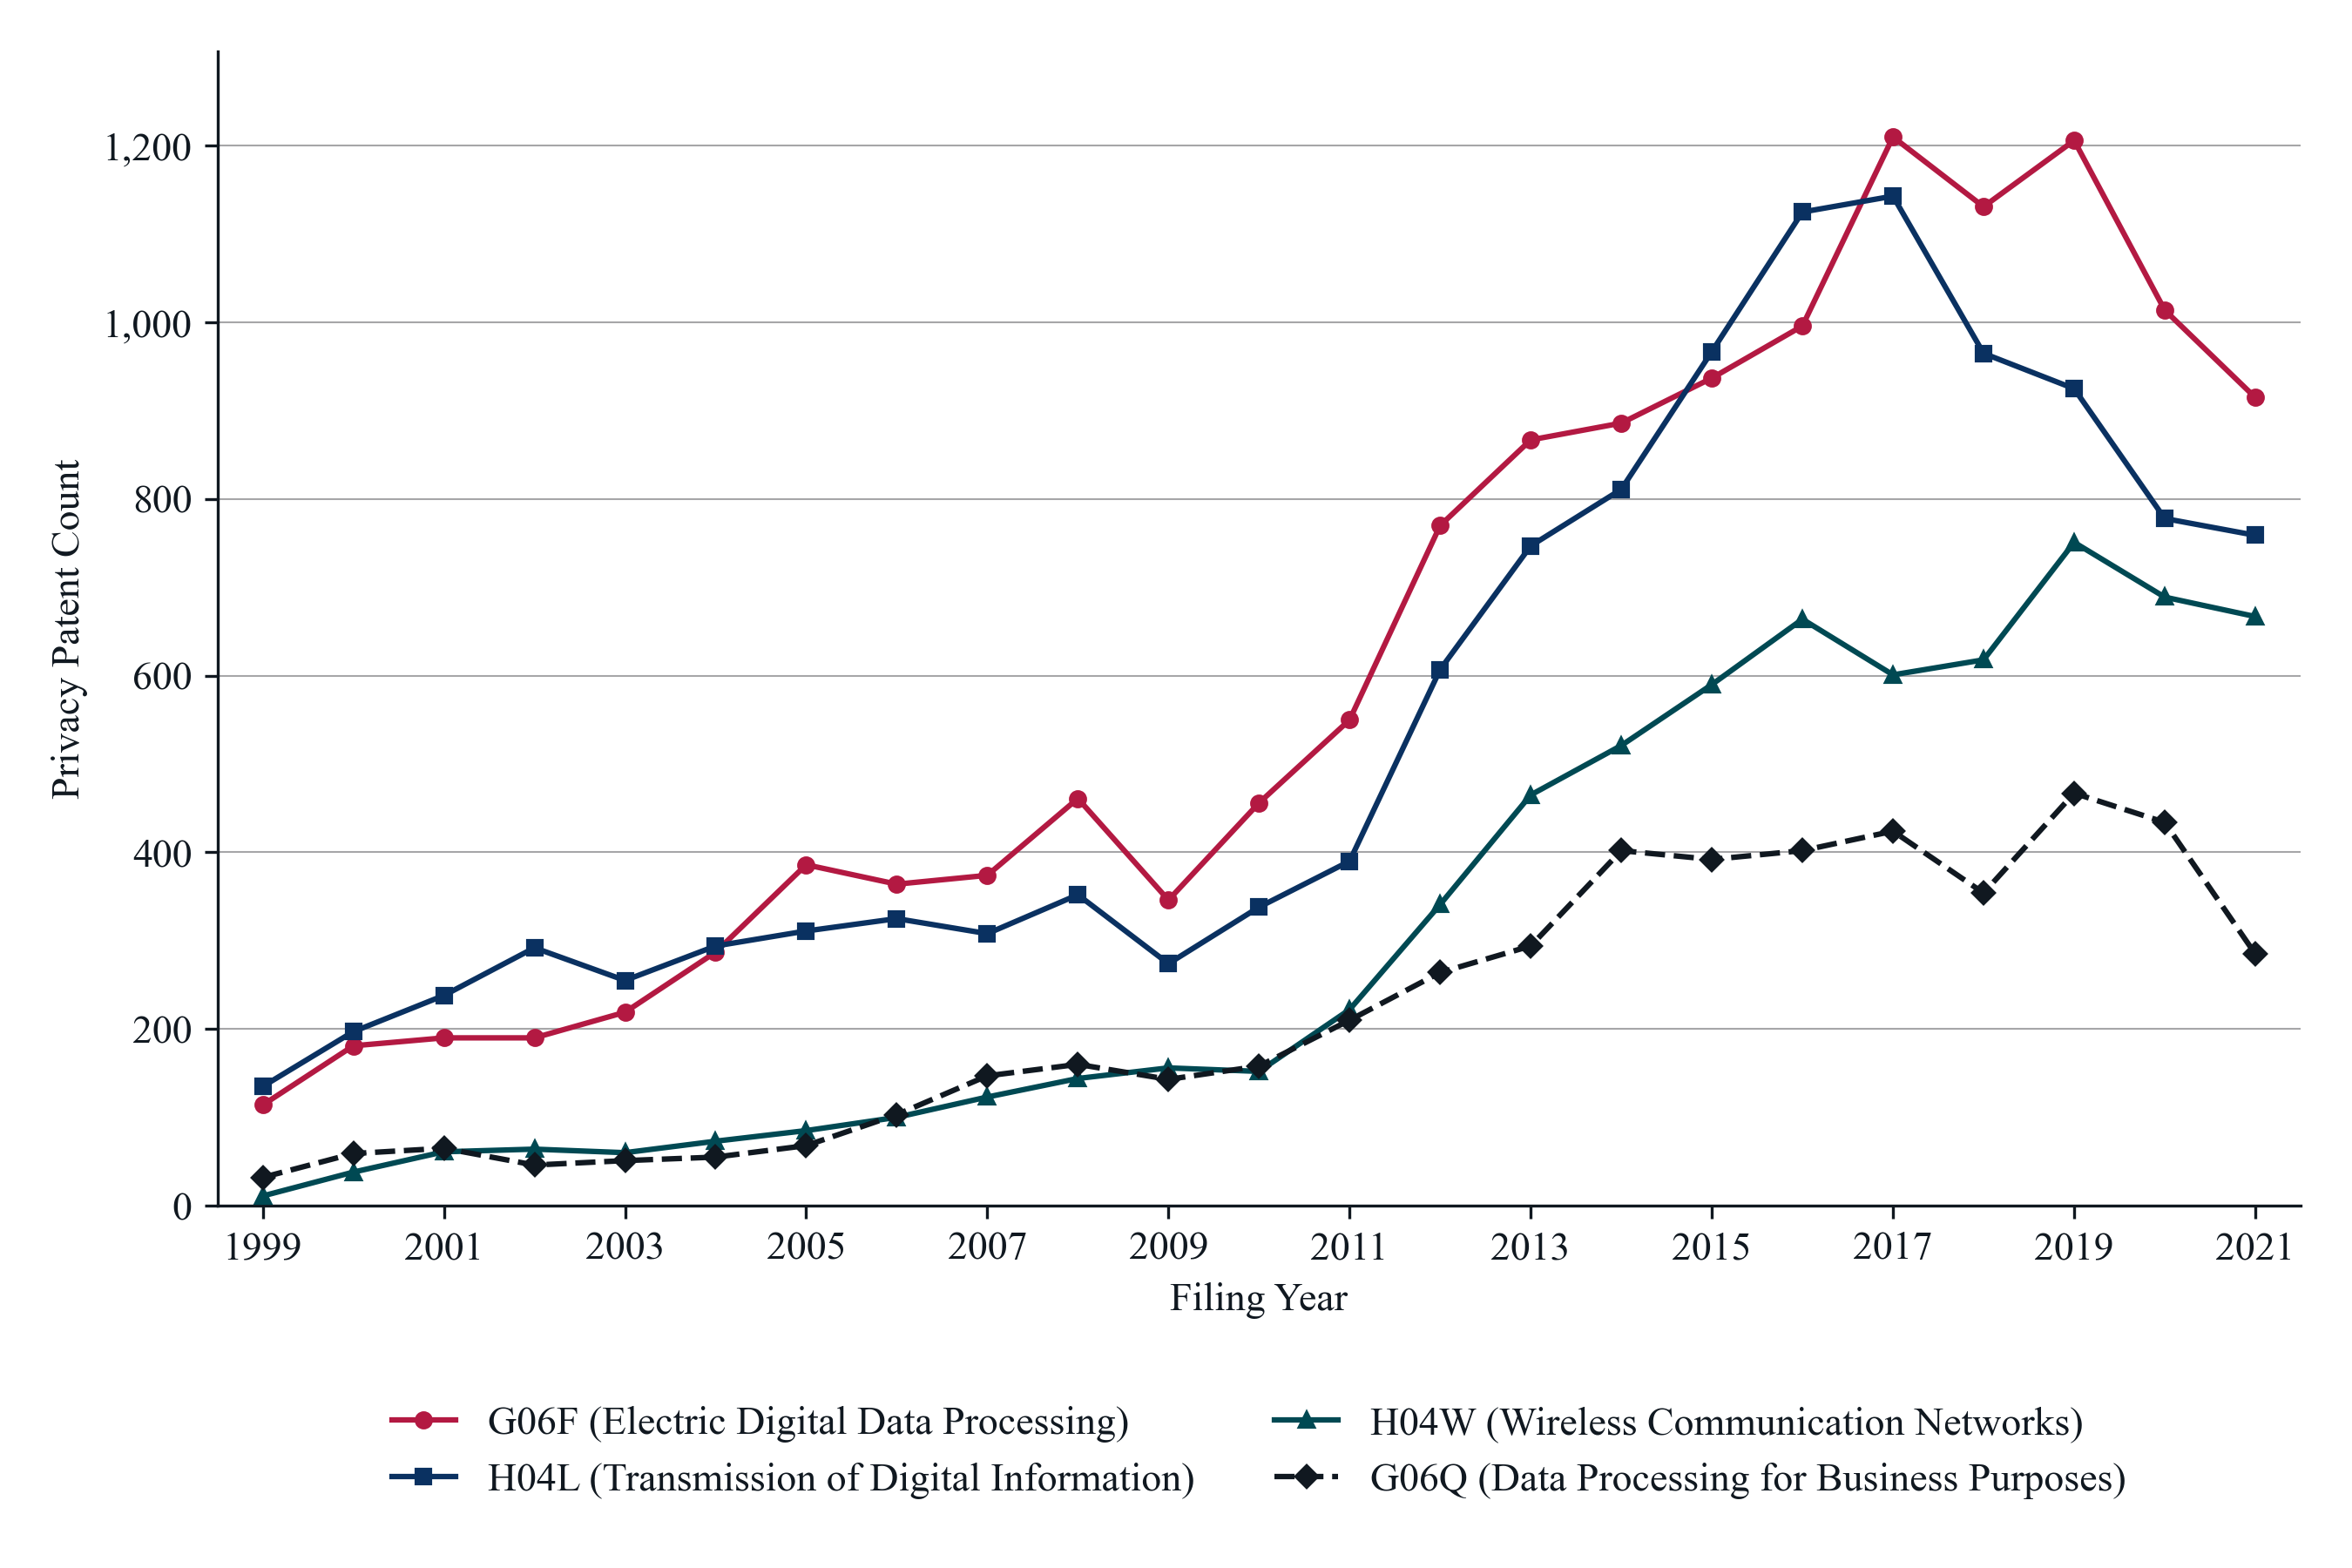

*Notes*: Each line is the number of privacy patents filed by the sample firms in each year, 1999 to 2021, whose listed codes fall in the CPC class: G06F, electric digital data processing; H04L, transmission of digital information; H04W, wireless communication networks; G06Q, information and communication technology adapted for administrative, commercial, financial, or managerial purposes. A privacy patent is a KPSS patent filed by a sample firm in 1999 to 2021 that carries at least one of the 72 CPC codes of the project's privacy code list (an exact match of the full code; a listed parent code does not pull in unlisted child codes). A patent with listed codes in two or more classes counts in each of those lines (4,453 patents), so the lines add up to more than the 33,986 privacy patents; totals over the period: G06F 14,050; H04L 12,536; H04W 7,196; G06Q 5,015. Counts in the last years are lower in part because KPSS covers granted patents and applications filed late in the period were not all granted by 2025. The sample firms are the 1,058 firms of the all-years T3 sample (every firm with a 10-K in the sample, fiscal 1999 to 2025), linked to their KPSS patents in T4.1.1.

*Source*: KPSS extended patent data (Kogan, Papanikolaou, Seru, and Stoffman, 2017, updated to 2025) with the authors' CPC match file; the privacy CPC code list in privacy_cpc/privacy_cpc_codes.xlsx; sample firms from the 10-K sample of T3 (SEC EDGAR); NAICS codes from Compustat through the CRSP-Compustat link; authors' calculations.

In [15]:
figure_number = 8
CLASS_STYLES = {"G06F": (RED, "o", "-"), "H04L": (BLUE, "s", "-"), "H04W": (MIDNIGHT_BLUE, "^", "-"), "G06Q": (BLACK, "D", "--")}  # color, marker, line pattern
figure_name = "fig_8_privacy_patent_count_by_filing_year_and_cpc_class"
title = f"Privacy Patents Filed by Sample Firms by Filing Year and CPC Class, {PERIOD_WORDS}"
x_title = "Filing Year"
y_title = "Privacy Patent Count"
LEGEND_COLUMNS = 2

figure, axis = plt.subplots()
figure.subplots_adjust(left=0.1, right=1 - MARGIN_INCHES / FIGURE_WIDTH, top=1 - MARGIN_INCHES / FIGURE_HEIGHT, bottom=0.25)
legend_handles = []
for cpc_class in CPC_CLASSES:
    color, marker, pattern = CLASS_STYLES[cpc_class]
    line, = axis.plot(by_year["filing_year"], by_year[f"n_privacy_patents_{cpc_class}"], color=color, linestyle=pattern, linewidth=1.5, marker=marker, markersize=4,
                      label=CPC_CLASS_TITLES[cpc_class], zorder=3)
    legend_handles.append(line)
axis.axhline(0, color=BLACK, linewidth=ZERO_LINE_WIDTH, zorder=2)
axis.set_xticks(range(PERIOD_START, PERIOD_END + 1, 2))
axis.set_xlim(PERIOD_START - 0.5, PERIOD_END + 0.5)
axis.set_ylim(0, by_year[[f"n_privacy_patents_{c}" for c in CPC_CLASSES]].max().max() * 1.08)
axis.yaxis.set_major_formatter(THOUSANDS)
axis.set_xlabel(x_title)
axis.set_ylabel(y_title)
axis.spines[["top", "right"]].set_visible(False)
# Layout: the Y-title starts 0.5 cm from the left edge; the X-title ends 0.5 cm above the bottom edge; nothing crosses the right or top margin.
figure.canvas.draw()
renderer = figure.canvas.get_renderer()
margin_pixels = MARGIN_INCHES * figure.dpi
left_shift = (margin_pixels - axis.yaxis.label.get_window_extent(renderer).x0) / figure.bbox.width
figure.subplots_adjust(left=figure.subplotpars.left + left_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
assert x_title_box.x0 >= margin_pixels and x_title_box.x1 <= figure.bbox.width - margin_pixels, f"X-title runs from {x_title_box.x0 / figure.dpi:.2f} to {x_title_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - x_title_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
axis_box = axis.get_tightbbox(renderer)
right_overflow = axis_box.x1 - (figure.bbox.width - margin_pixels)
top_overflow = axis_box.y1 - (figure.bbox.height - margin_pixels)
if right_overflow > 0 or top_overflow > 0:
    figure.subplots_adjust(right=figure.subplotpars.right - max(right_overflow, 0) / figure.bbox.width, top=figure.subplotpars.top - max(top_overflow, 0) / figure.bbox.height)
    figure.canvas.draw()
    axis_box = axis.get_tightbbox(renderer)
assert axis_box.x1 <= figure.bbox.width - margin_pixels + 1 and axis_box.y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the right or top margin"
# Legend: its top 0.5 cm below the X-title, its bottom 0.5 cm above the bottom edge; the bottom margin grows to make room, which moves the X-title and the legend together.
x_title_box = axis.xaxis.label.get_window_extent(renderer)
axis_center = (axis.get_window_extent(renderer).x0 + axis.get_window_extent(renderer).x1) / 2 / figure.bbox.width
legend = figure.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height),
                       bbox_transform=figure.transFigure, ncol=LEGEND_COLUMNS, frameon=False, handlelength=1.6, columnspacing=2.0)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert legend_box.x0 >= margin_pixels and legend_box.x1 <= figure.bbox.width - margin_pixels, f"legend runs from {legend_box.x0 / figure.dpi:.2f} to {legend_box.x1 / figure.dpi:.2f} inches"
bottom_shift = (margin_pixels - legend_box.y0) / figure.bbox.height
figure.subplots_adjust(bottom=figure.subplotpars.bottom + bottom_shift)
figure.canvas.draw()
x_title_box = axis.xaxis.label.get_window_extent(renderer)
legend.set_bbox_to_anchor((axis_center, (x_title_box.y0 - margin_pixels) / figure.bbox.height), transform=figure.transFigure)
figure.canvas.draw()
legend_box = legend.get_window_extent(renderer)
assert abs(legend_box.y0 - margin_pixels) <= 2, f"legend bottom at {legend_box.y0 / figure.dpi:.2f} inches"
assert axis.get_tightbbox(renderer).y1 <= figure.bbox.height - margin_pixels + 1, "an element crosses the top margin"

class_totals = "; ".join(f"{c} {int(privacy_patents[f'in_{c}'].sum()):,}" for c in CPC_CLASSES)
notes = (f"Each line is the number of privacy patents filed by the sample firms in each year, {PERIOD_WORDS}, whose listed codes fall in the CPC class: G06F, electric digital data "
         "processing; H04L, transmission of digital information; H04W, wireless communication networks; G06Q, information and communication technology adapted for administrative, "
         f"commercial, financial, or managerial purposes. {PRIVACY_WORDS}. A patent with listed codes in two or more classes counts in each of those lines ({n_two_classes:,} patents), "
         f"so the lines add up to more than the {len(privacy_patents):,} privacy patents; totals over the period: {class_totals}. Counts in the last years are lower in part because KPSS "
         "covers granted patents and applications filed late in the period were not all granted by 2025."
         f" The sample firms are {SAMPLE_WORDS}.")
for extension in ["png", "svg", "pdf"]:
    figure.savefig(OUTPUT_FOLDER / f"{figure_name}.{extension}", dpi=EXPORT_DPI)
plt.close(figure)
display(Markdown(f"**Figure {figure_number}. {title}**"))
display(Image(filename=str(OUTPUT_FOLDER / f"{figure_name}.png"), width=900))
display(Markdown(f"*Notes*: {notes}"))
display(Markdown(f"*Source*: {SOURCE}."))
